In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load("../../../hists/UL_lep_monotop_v1_test_preVFP_2016.scaled")
data={
    '2016':{
        'sre': 'SingleElectron',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'SingleElectron',
        'ttbare': 'SingleElectron',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [3]:
import re
cr = "wjete"
systematics =[]
for syst in bkg_hists['template'].integrate('region', cr).identifiers('systematic'):
    if (re.search("Up$", str(syst))):
        systematics.append(str(syst)[:-2])
        
for proc in signal_hists['template'].identifiers("process"):
    print("*****",proc, "******")
    for syst in  systematics:
        if ("ew" in syst) or ("qcd" in syst) or ("mix" in syst) or ("muR" in syst) or("muF" in syst):
            continue
        print(syst)
        up = signal_hists['template'].integrate('region', cr).integrate('process', proc).integrate('systematic', syst+"Up").sum("npvs").values()[()]
        down = signal_hists['template'].integrate('region', cr).integrate('process', proc).integrate('systematic', syst+"Down").sum("npvs").values()[()]
        print("  up    ",up)
        print()
        print("  dn   ",down)

***** Mphi-1995_Mchi-1000 ******
FSR
  up     [  0.           0.           0.           8.78991597   4.92958371
   5.45120283   0.         -16.20451127 102.59141271   0.
  37.53538106]

  dn    [ 0.          0.          0.         20.81091709 15.54113711 10.42541122
  0.         -9.86774089 14.26660927  0.         62.82598982]
ISR
  up     [  0.           0.           0.          17.56102574  15.53466817
   9.14949317   0.         -11.86343668  31.83111517   0.
  57.39334187]

  dn    [  0.           0.           0.          15.79910722   8.11136687
   9.52608317   0.         -13.66583463  31.74675975   0.
  48.1219832 ]
JES
  up     [ 0.          0.          0.          2.20628705  0.74143201 20.70967744
  9.98794818  2.02373534  2.92265451  2.81833989 18.50987498]

  dn    [ 0.          0.         14.07404322  0.55395649 15.87601583 13.39775417
  2.74561123  1.09317467  3.04321305  0.6130728  15.55884382]
L1Prefire
  up     [  0.           0.           0.          16.81108644  11.117

  up     [ 0.          0.          0.         -3.8845862   4.00995205  4.24316438
 14.65717245  0.          0.         35.43595691 29.66091116]

  dn    [ 0.          0.          0.         -3.63021656  3.95064618  4.18141194
 14.22222456  0.          0.         34.69178523 28.21304669]
btag
  up     [ 0.          0.          0.         -3.73942775  3.98224357  4.21563308
 14.41089255  0.          0.         34.95882751 28.81904933]

  dn    [ 0.          0.          0.         -3.73942775  3.98224357  4.21563308
 14.41089255  0.          0.         34.95882751 28.81904933]
id_e
  up     [ 0.          0.          0.         -3.79919615  4.03036608  4.26335151
 14.58386643  0.          0.         35.38127947 43.24535214]

  dn    [ 0.          0.          0.         -3.67965934  3.93412106  4.16791465
 14.23791867  0.          0.         34.53637556 14.39274652]
isolation_e
  up     [ 0.          0.          0.         -3.73942775  3.98224357  4.21563308
 14.41089255  0.          0.    

In [10]:
a=sum(data_hists['mT_corrected'].integrate('systematic', 'nominal').integrate('region', 'wjete').integrate('process').values()[()])

In [10]:
signal_hists['template']

<Hist (process,region,systematic,npvs,mT_corrected) instance at 0x7fe8e41eb1d0>

In [8]:
sys = 'nominal'
region = 'wjete'
print(region)
SUM_data = sum(signal_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleElectron').values()[()])
print('SingleElectron',':', SUM_data)

tmp = 0
for process in bkg_hists["mT_corrected"].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp)   

wjete


KeyError: ()

In [3]:
sys = 'nominal'
region = 'ttbare'
print(region)
SUM_data = sum(data_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleElectron').values()[()])
print('SingleElectron',':', SUM_data)

tmp = 0
for process in bkg_hists[key].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp) 

ttbare
SingleElectron : 0.0


NameError: name 'key' is not defined

In [ ]:
sys = 'nominal'
region = 'ttbarm'
print(region)
SUM_data = sum(data_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleMuon').values()[()])
print('SingleMuon',':', SUM_data)

tmp = 0
for process in bkg_hists[key].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp)

In [ ]:
sys = 'nominal'
region = 'wjetm'
print(region)
SUM_data = sum(data_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', 'SingleMuon').values()[()])
print('SingleMuon',':', SUM_data)

tmp = 0
for process in bkg_hists[key].identifiers('process'):
    
    SUM_bkg = sum(bkg_hists['mT_corrected'].integrate('systematic', sys).integrate('region', region).integrate('process', process).values()[()])
    tmp+=SUM_bkg
    print(process,":",SUM_bkg)
print("Sum MC:", tmp)
print("Data/MC:", SUM_data/tmp)

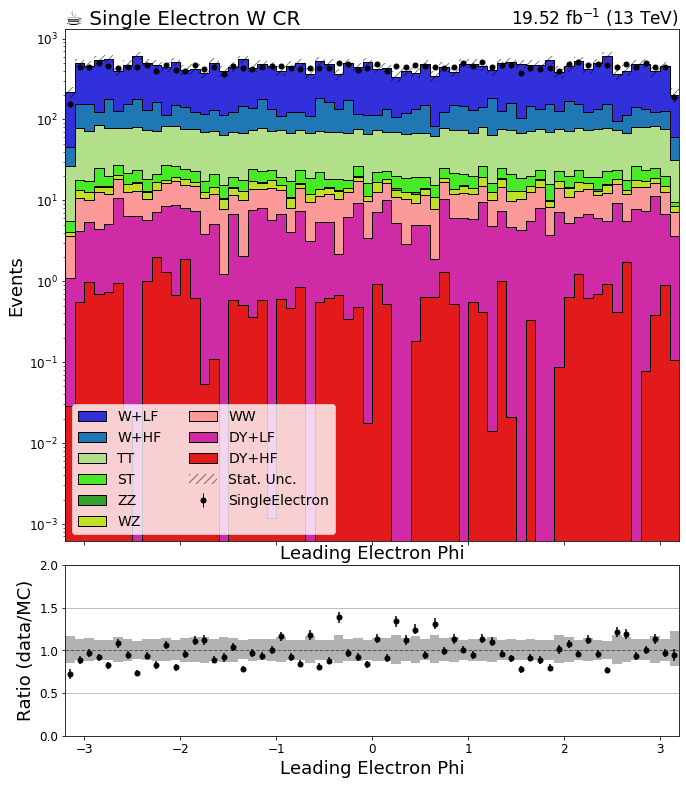

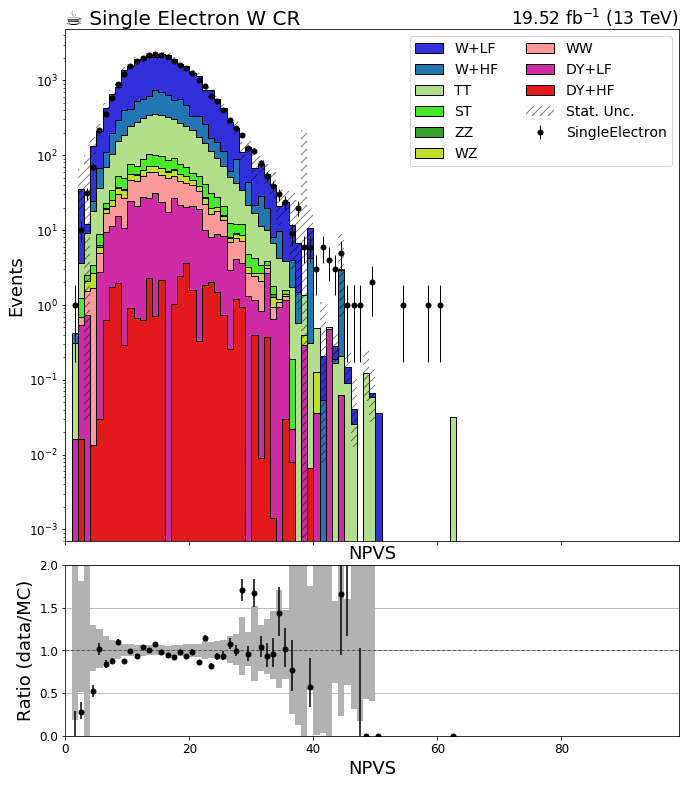

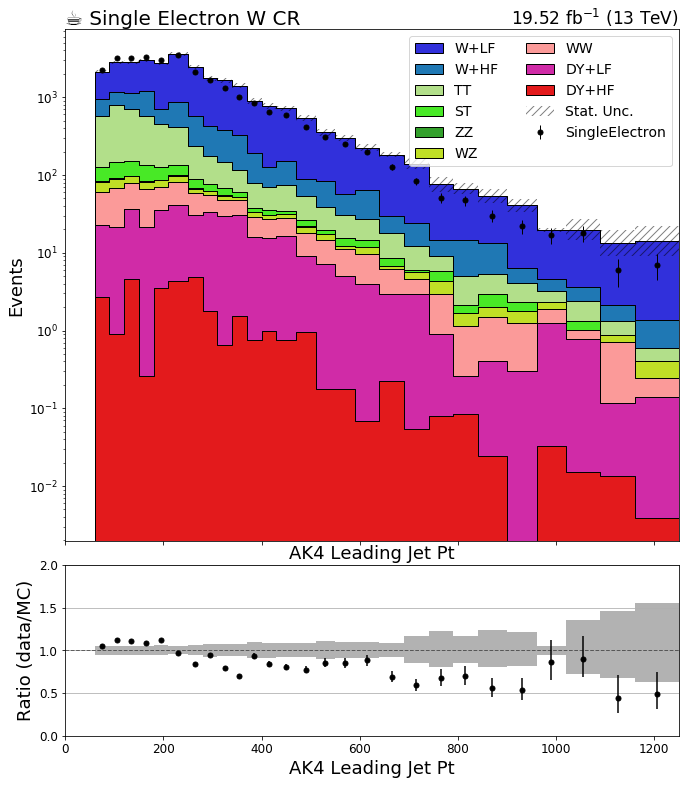

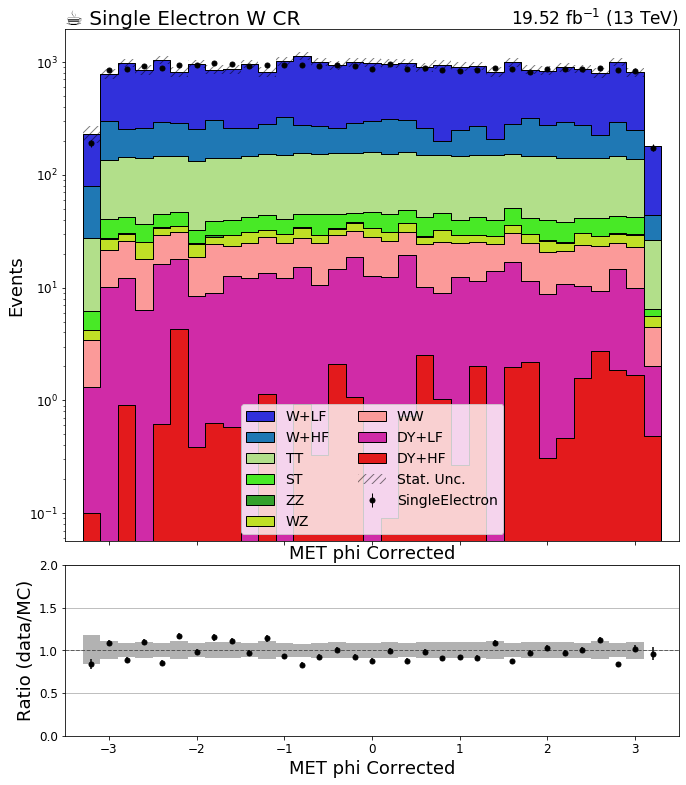

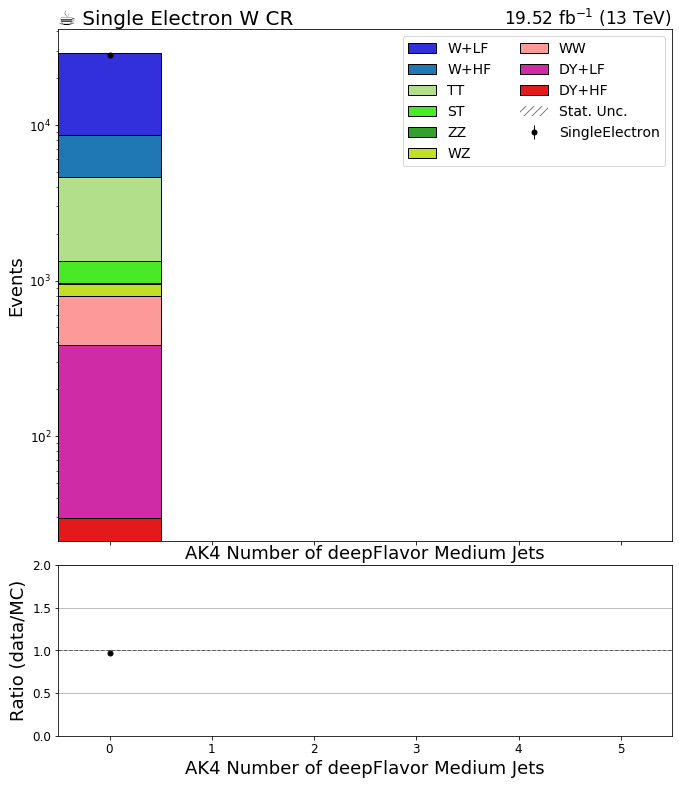

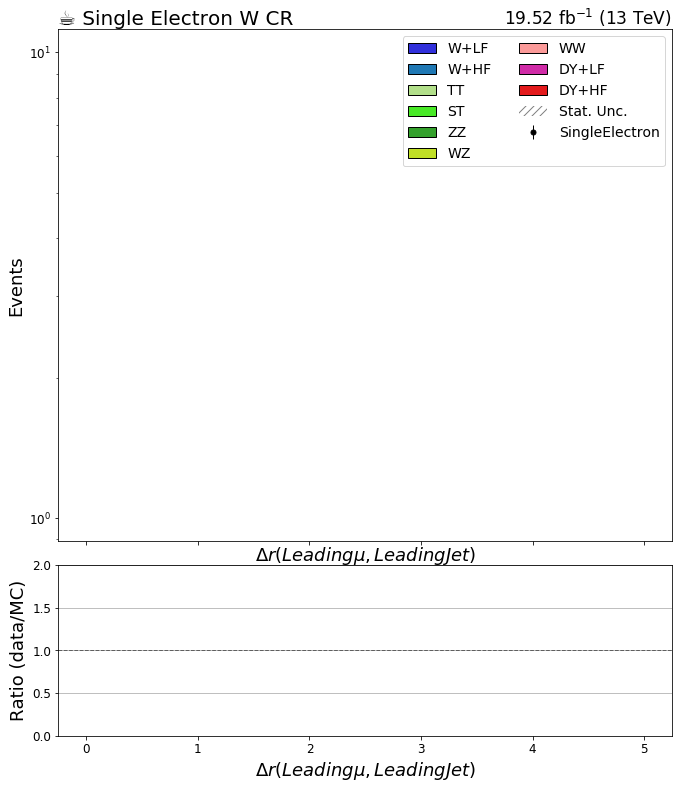

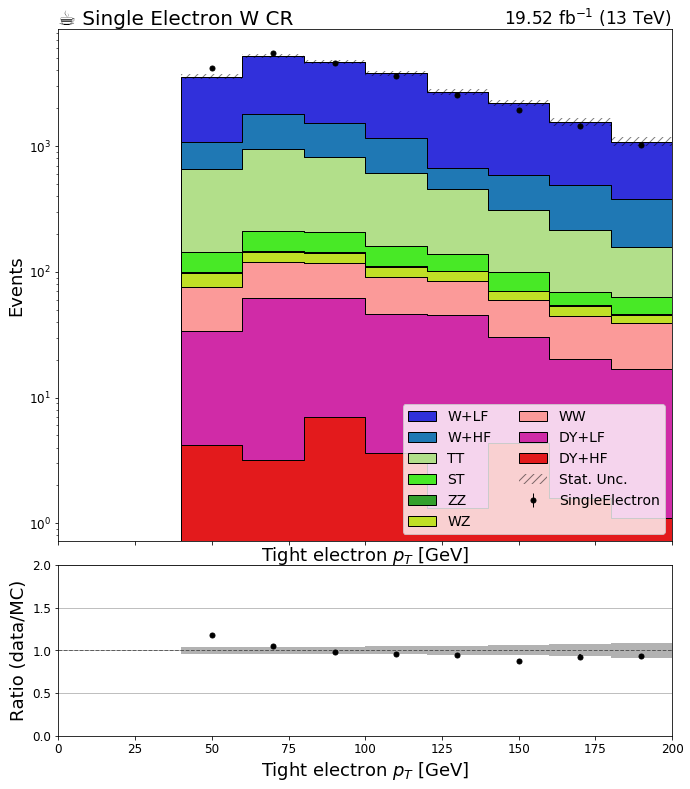

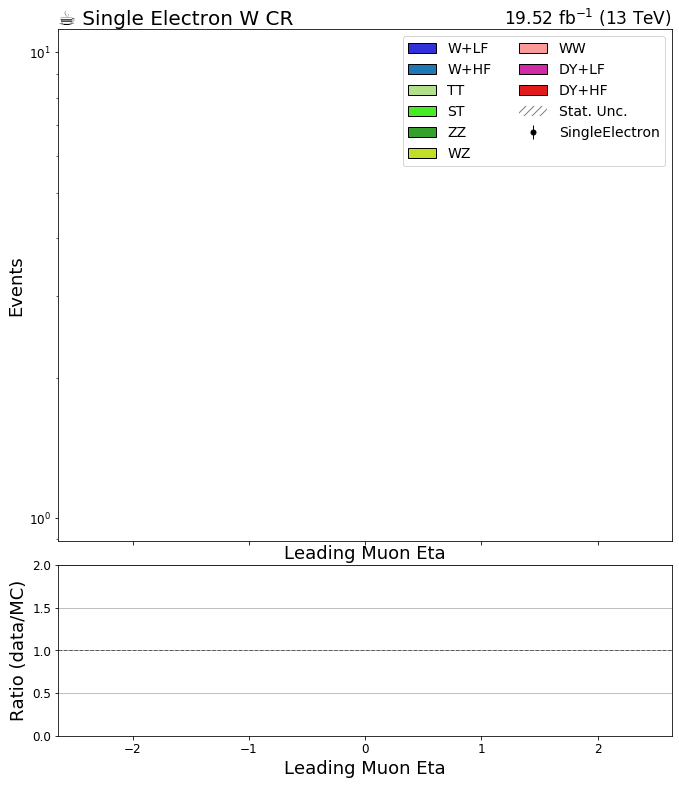

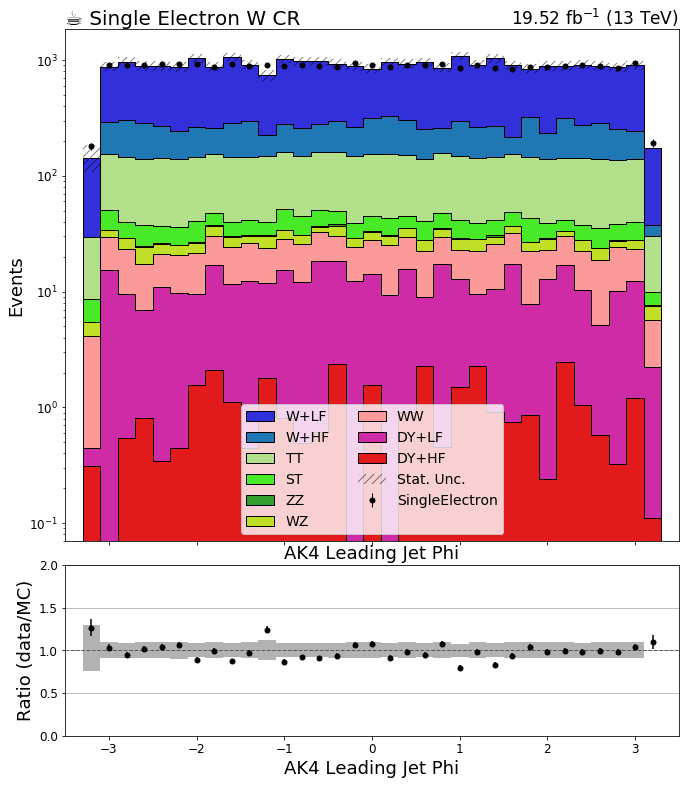

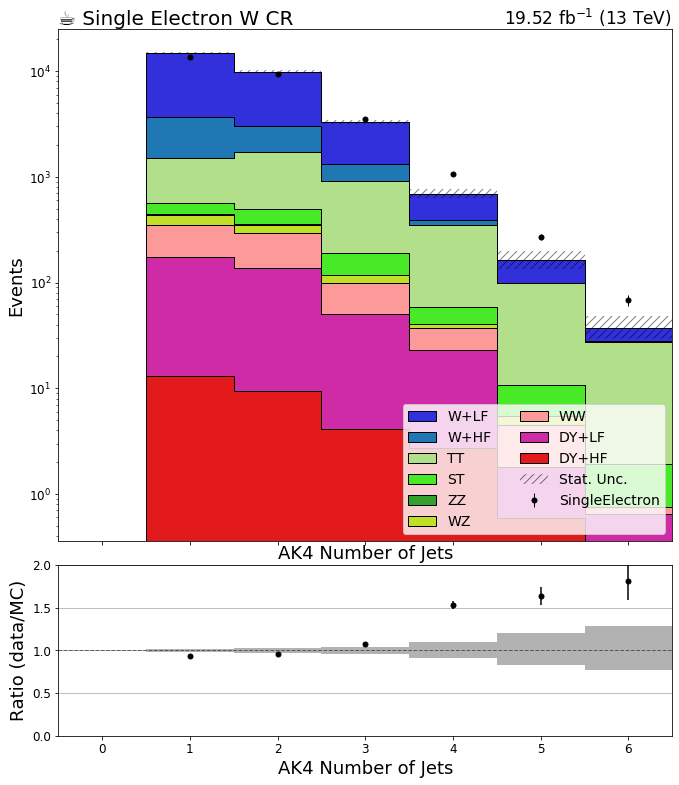

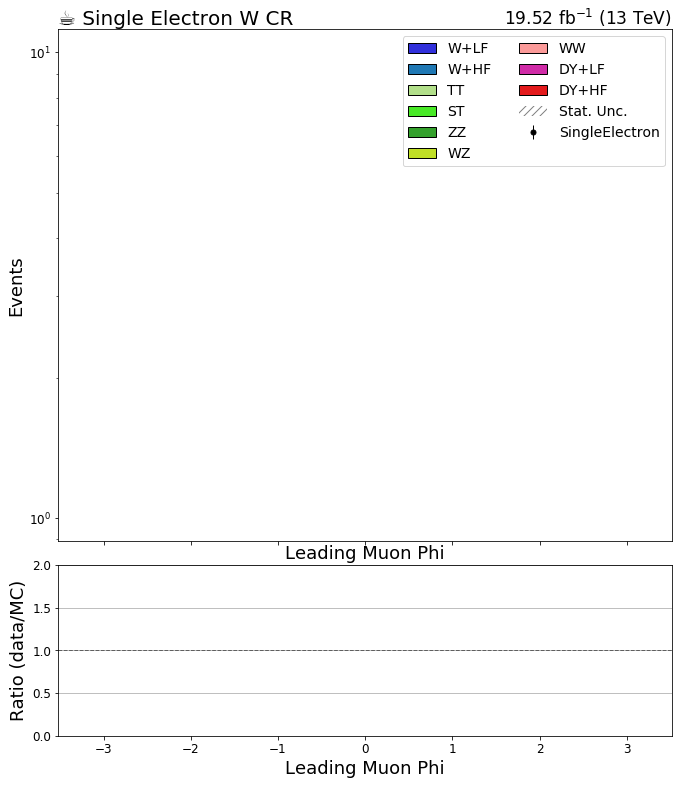

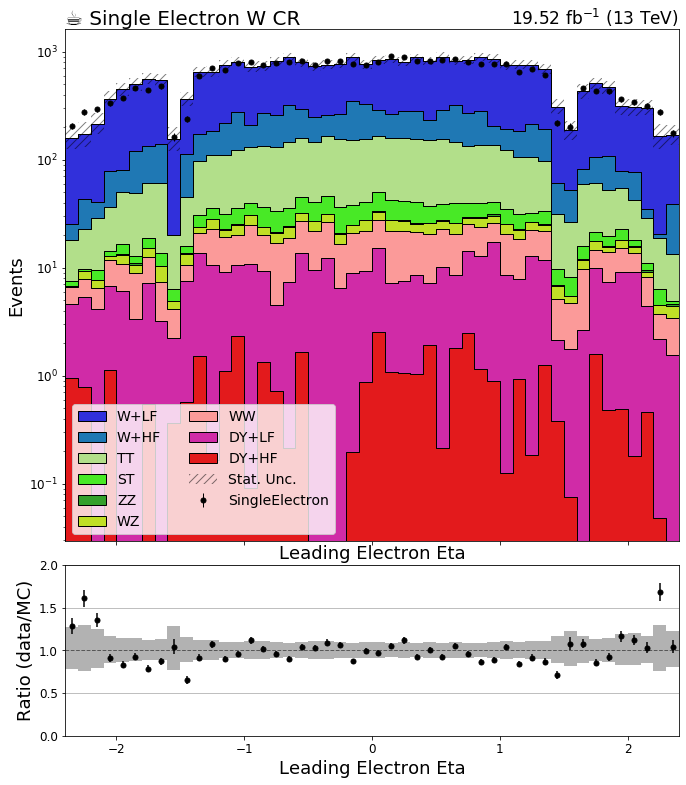

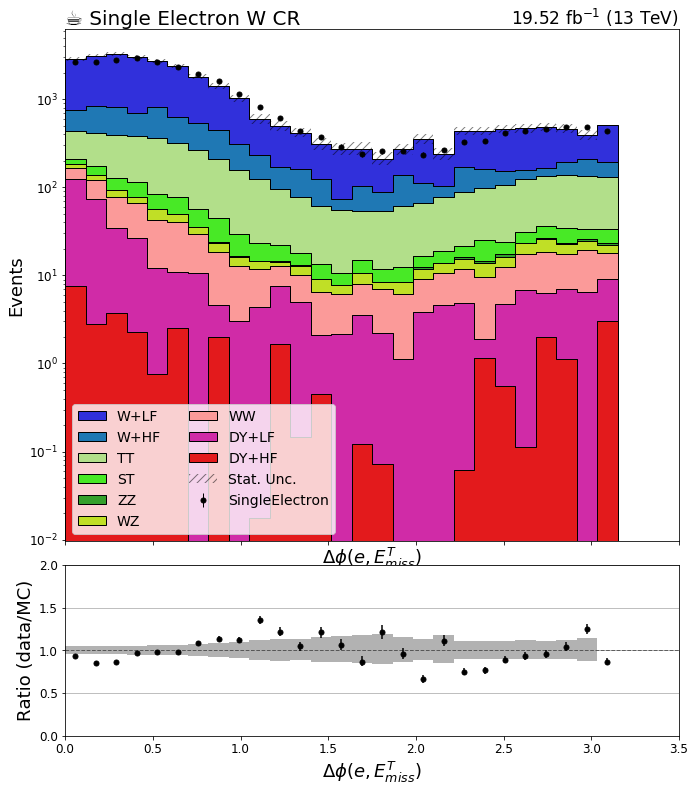

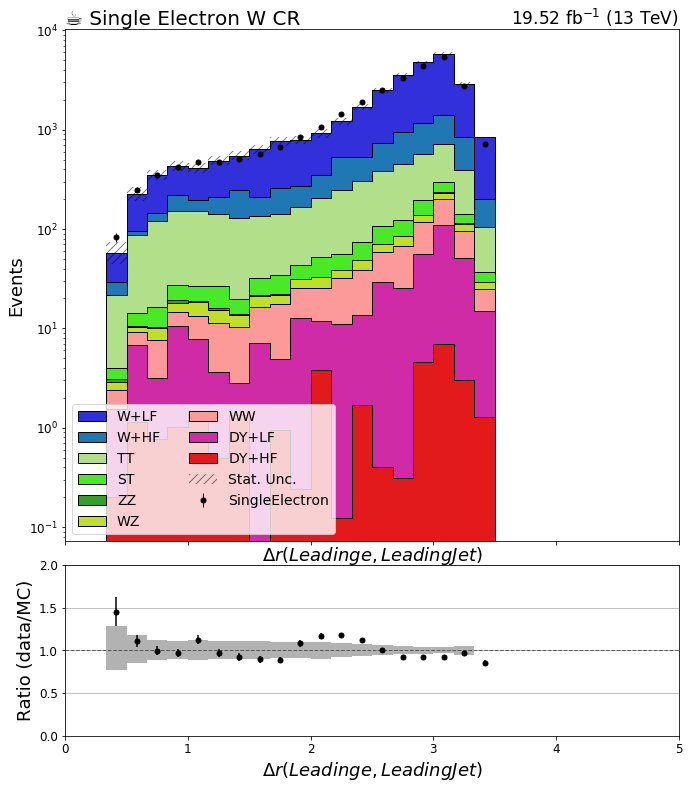

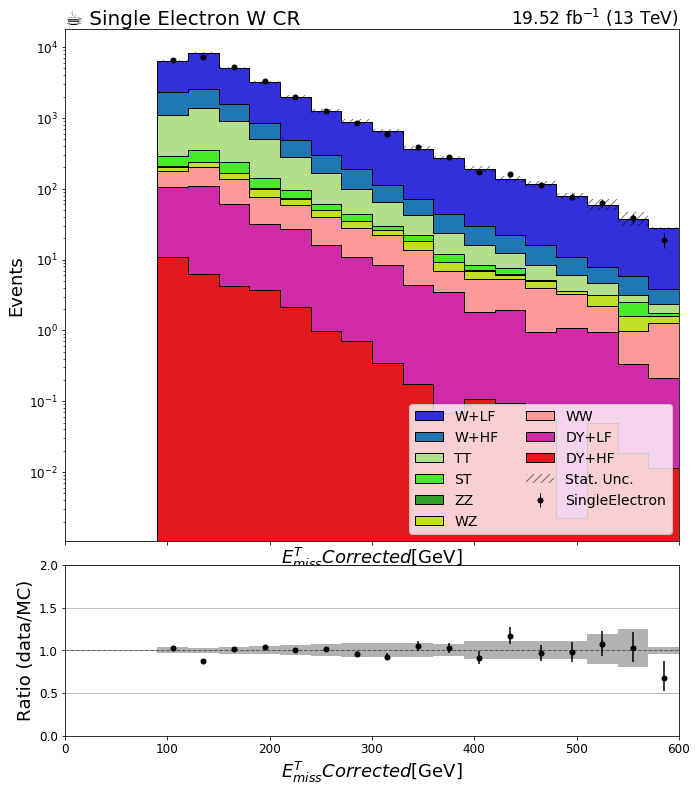

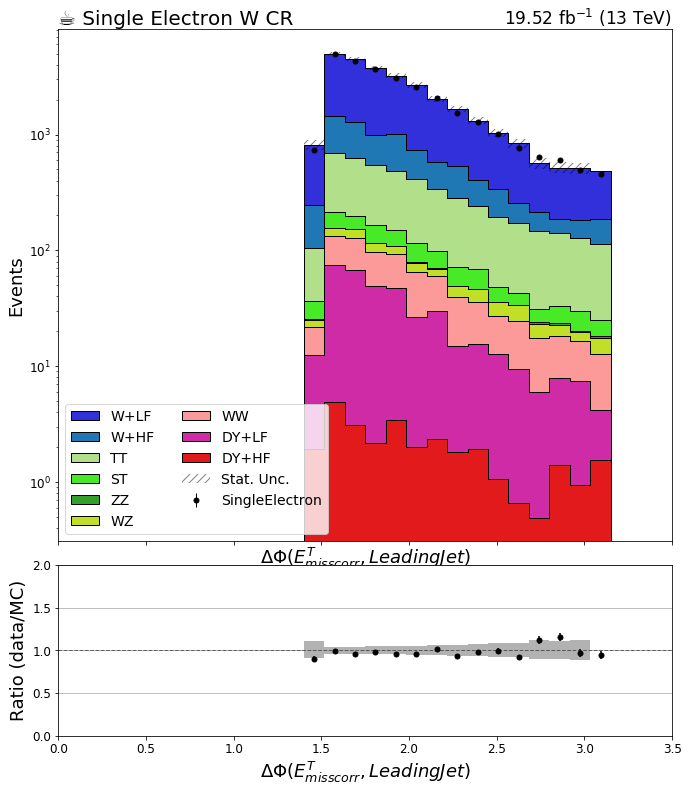

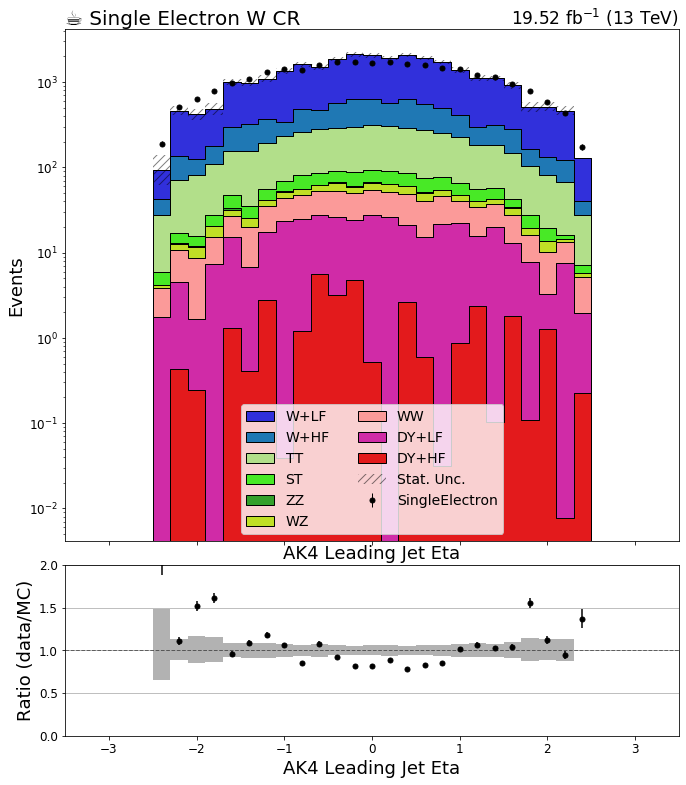

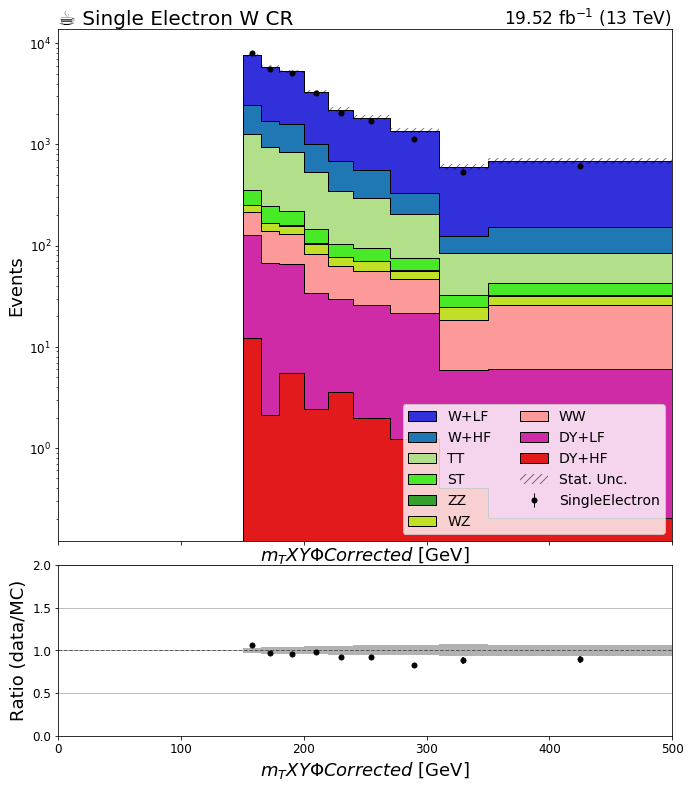

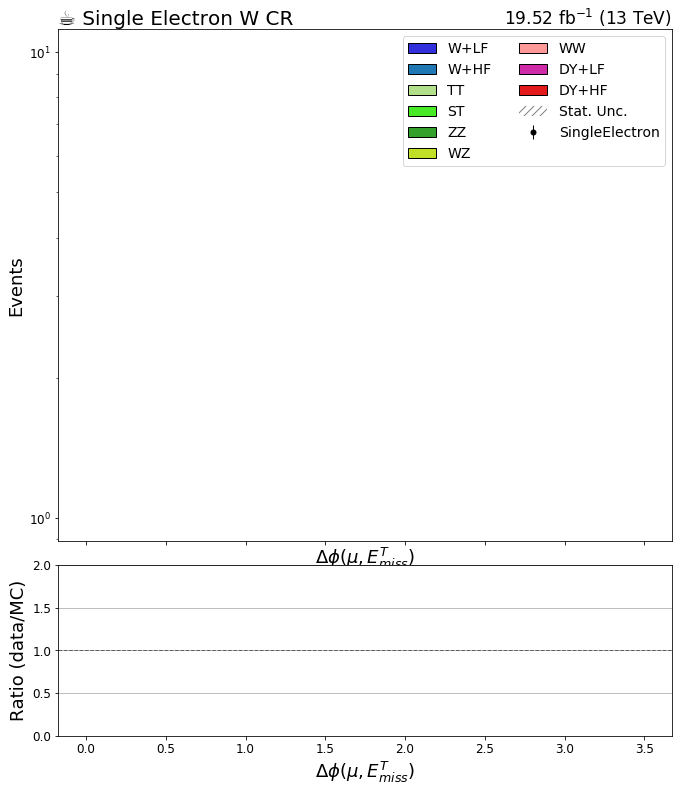

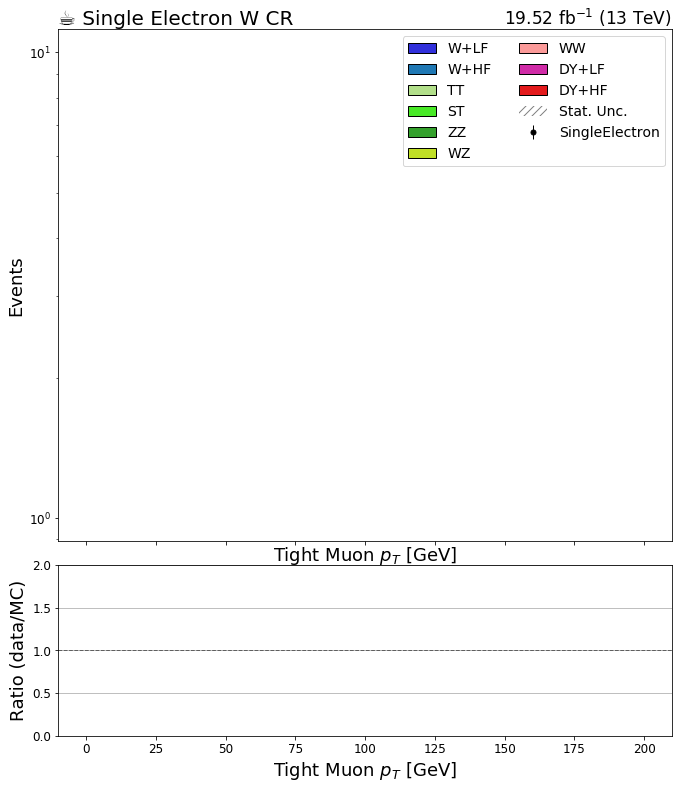

In [3]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi_Corr_Met_LJ' in key:continue
#     if 'mu_pT' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
#         print(j, key)
#         print(data_hists[key].integrate("systematic").integrate('region',j)[data[year][str(j)]].values())
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

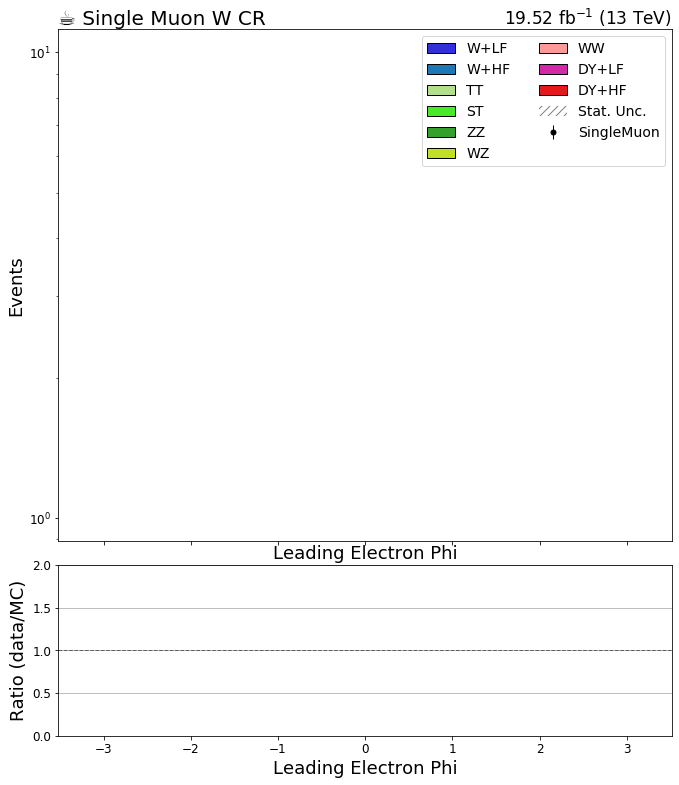

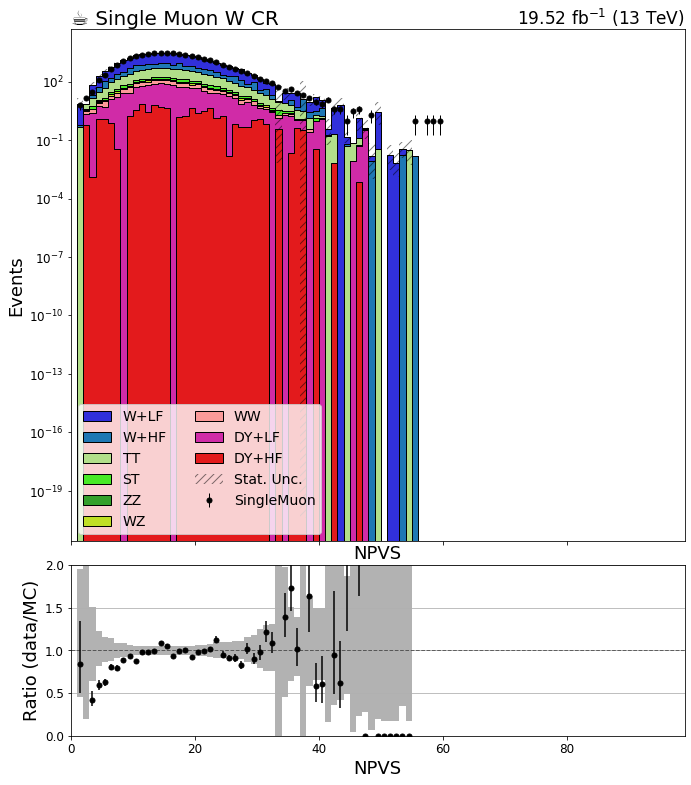

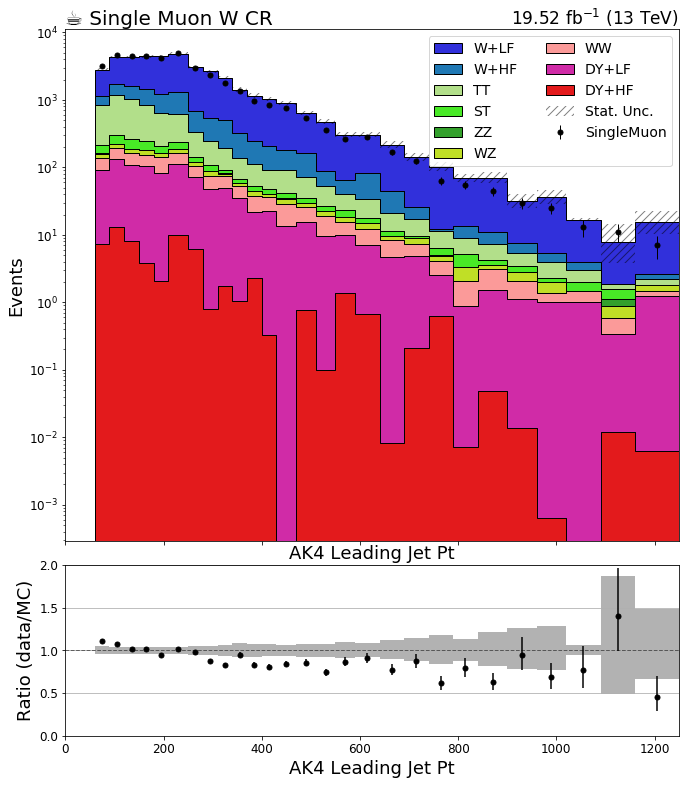

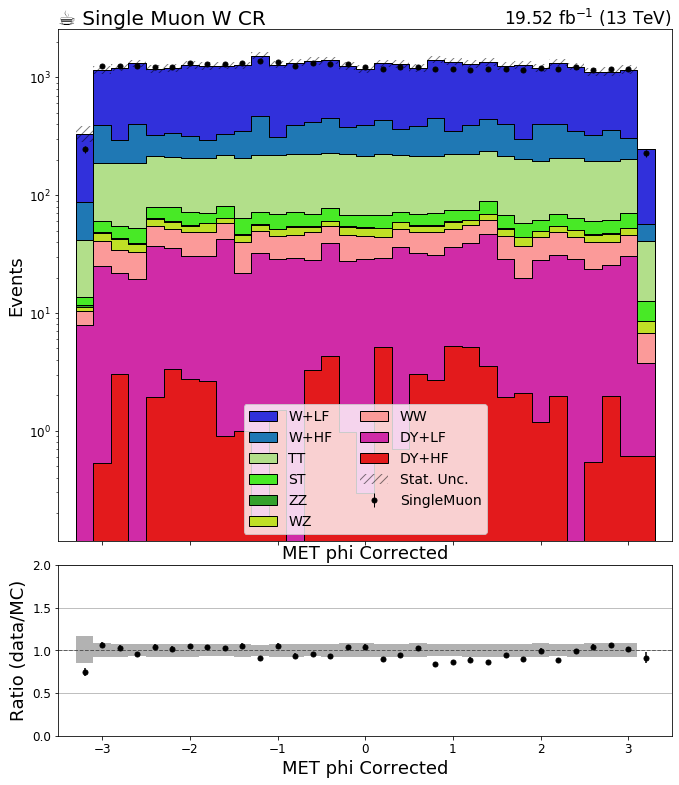

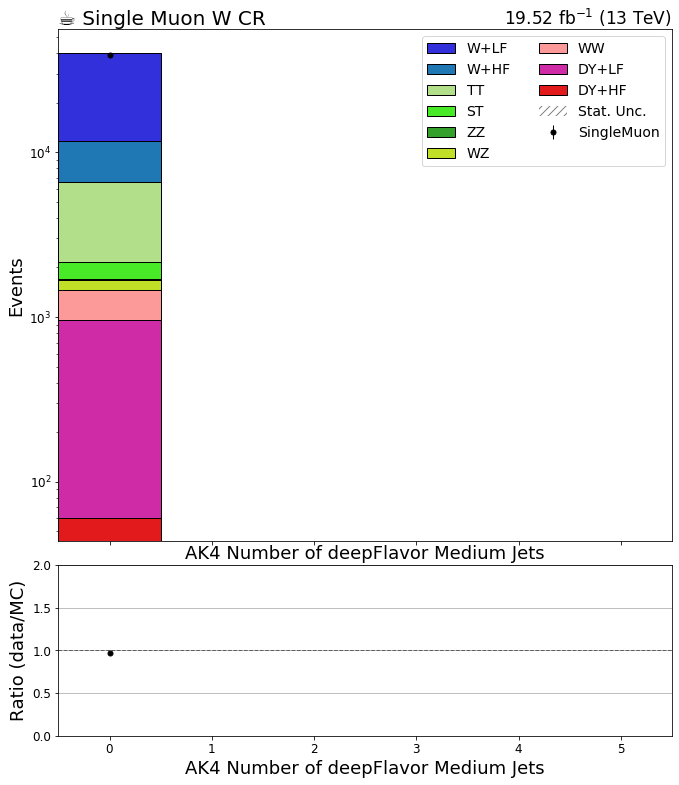

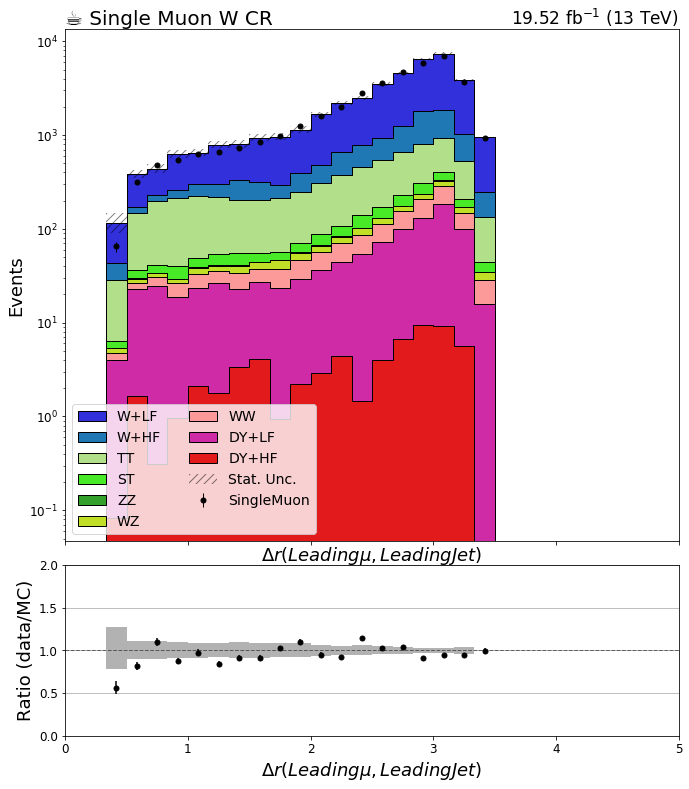

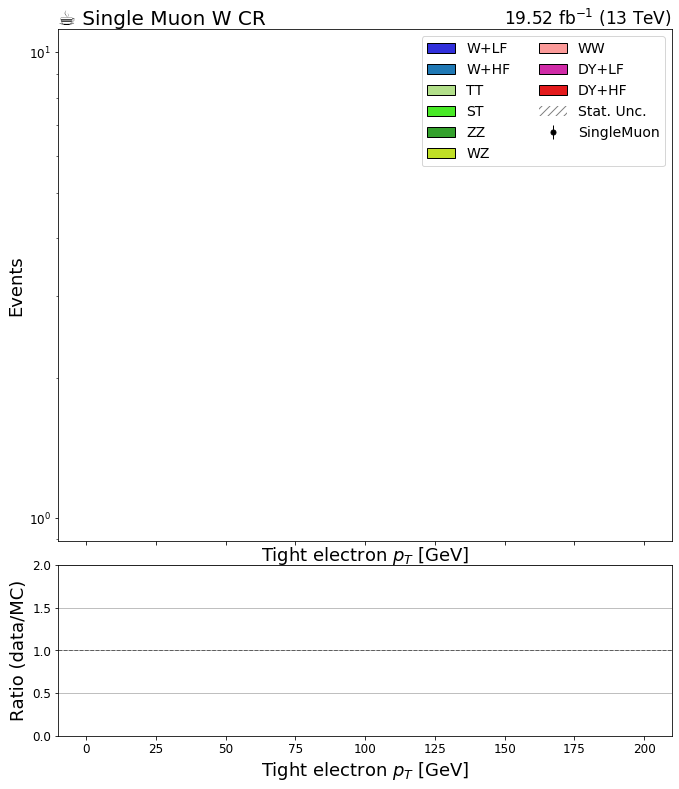

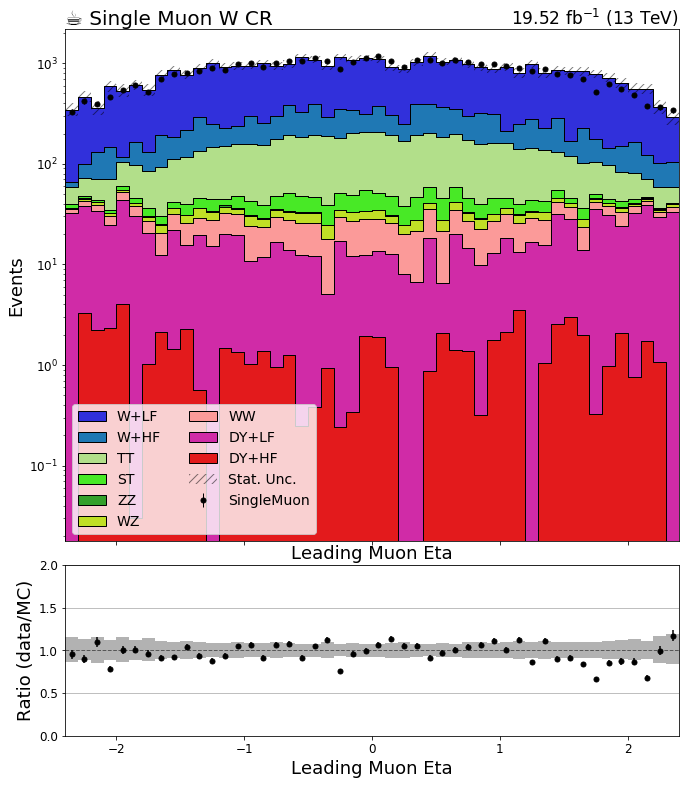

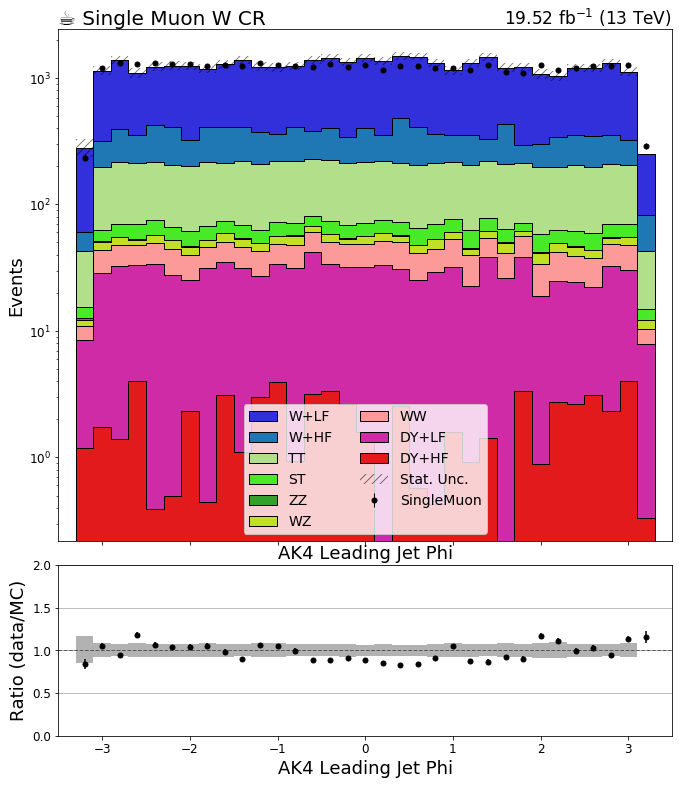

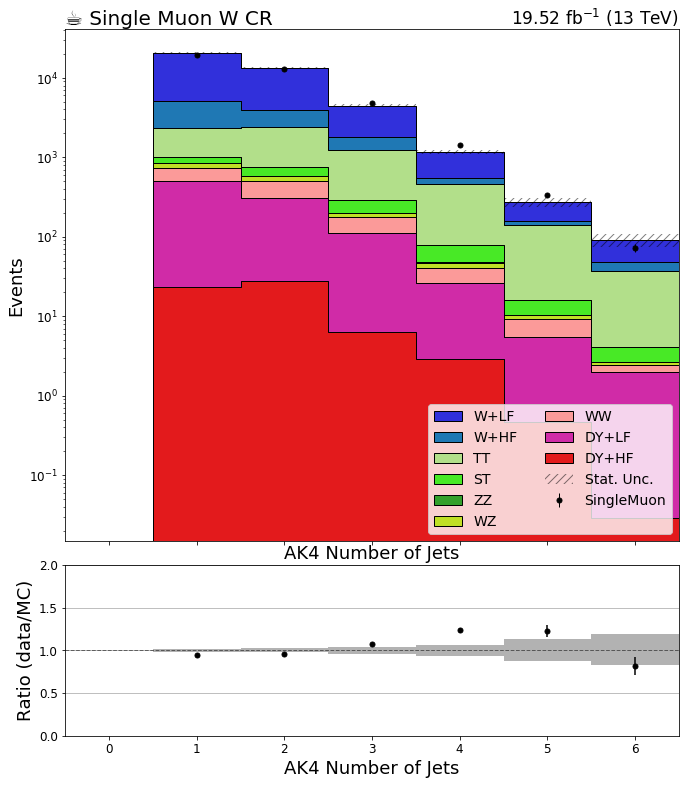

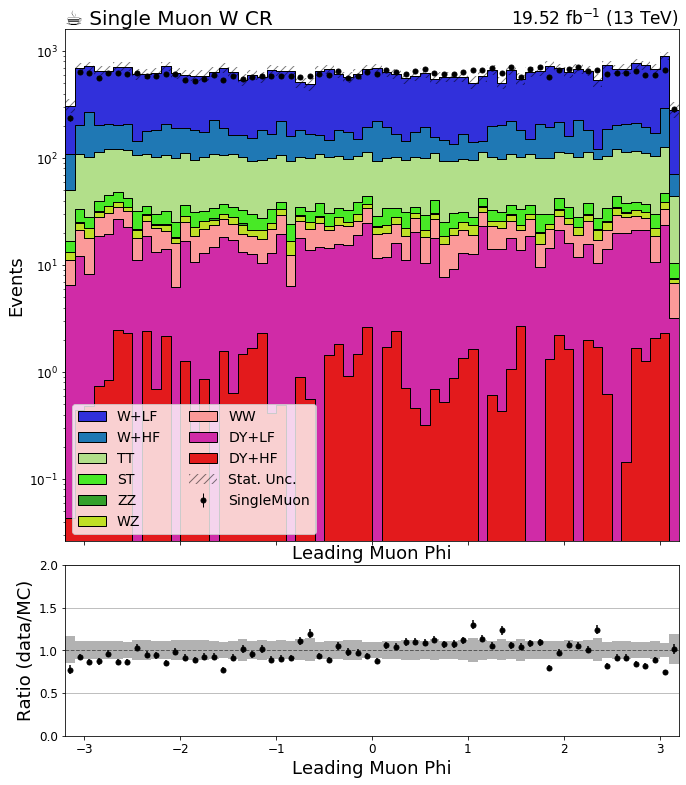

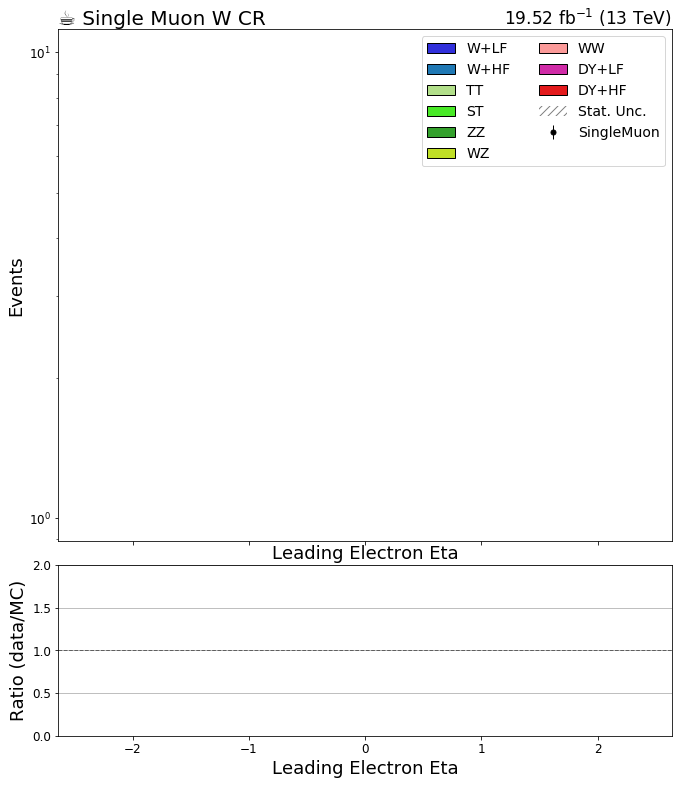

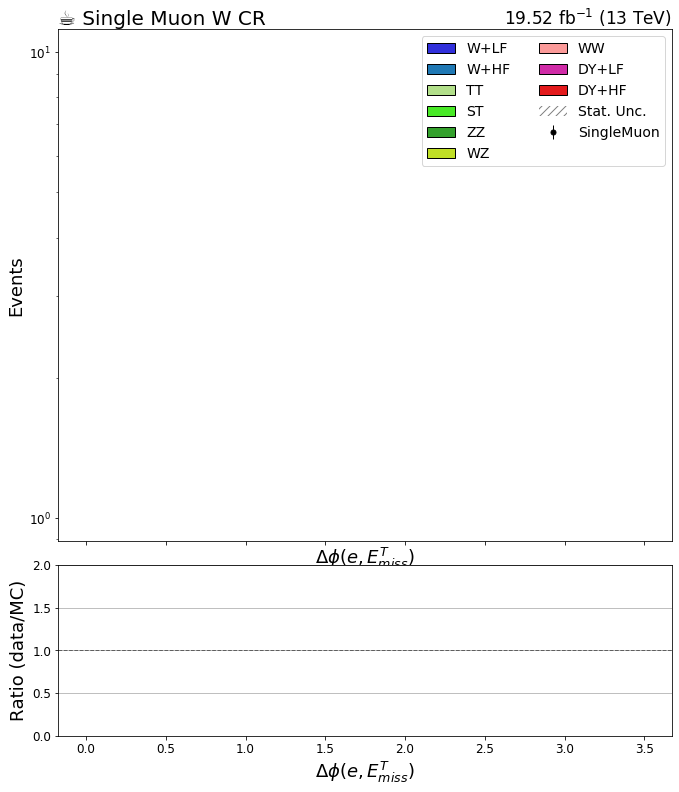

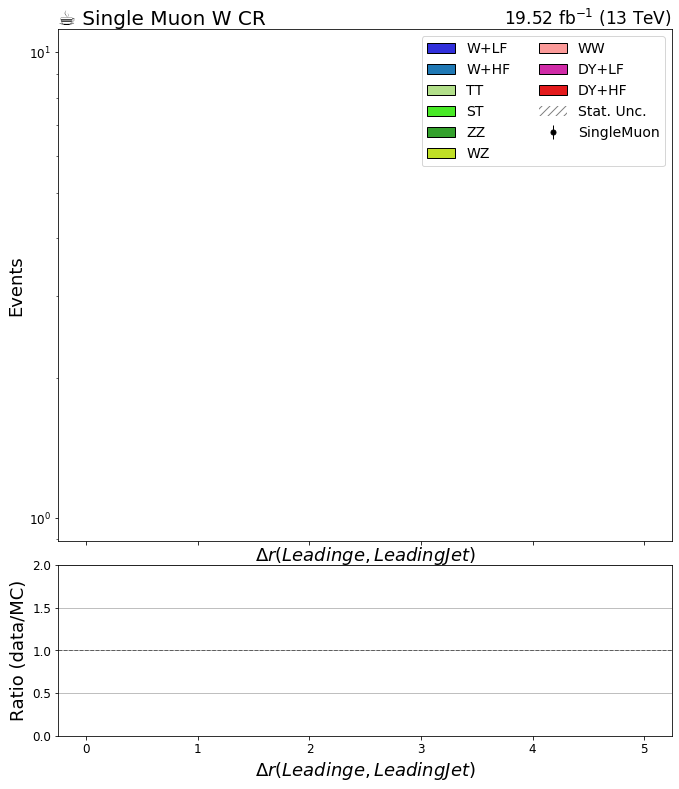

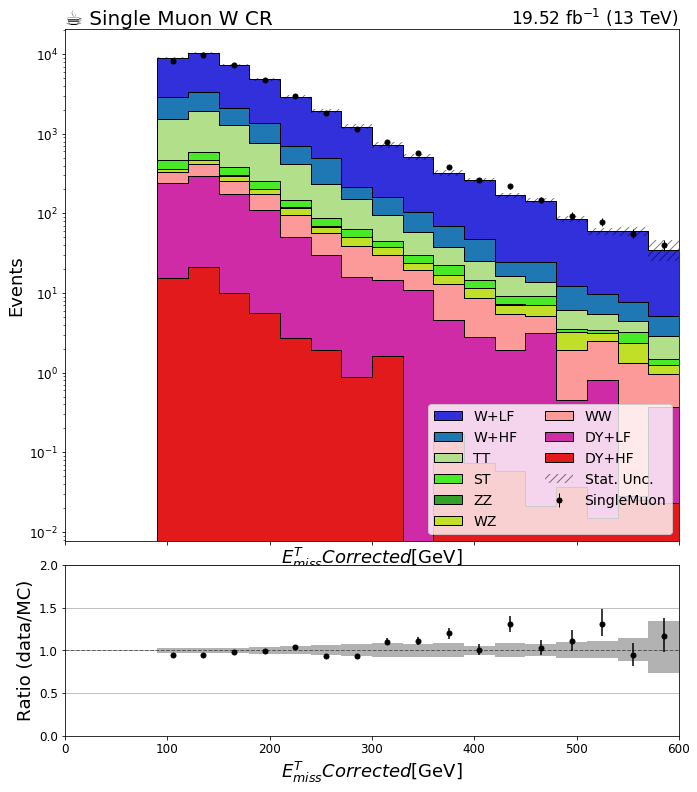

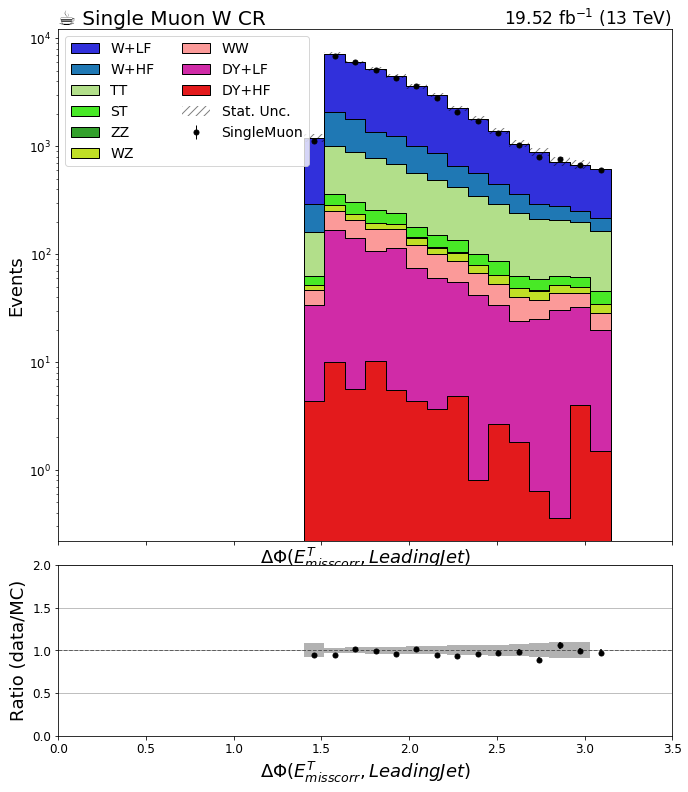

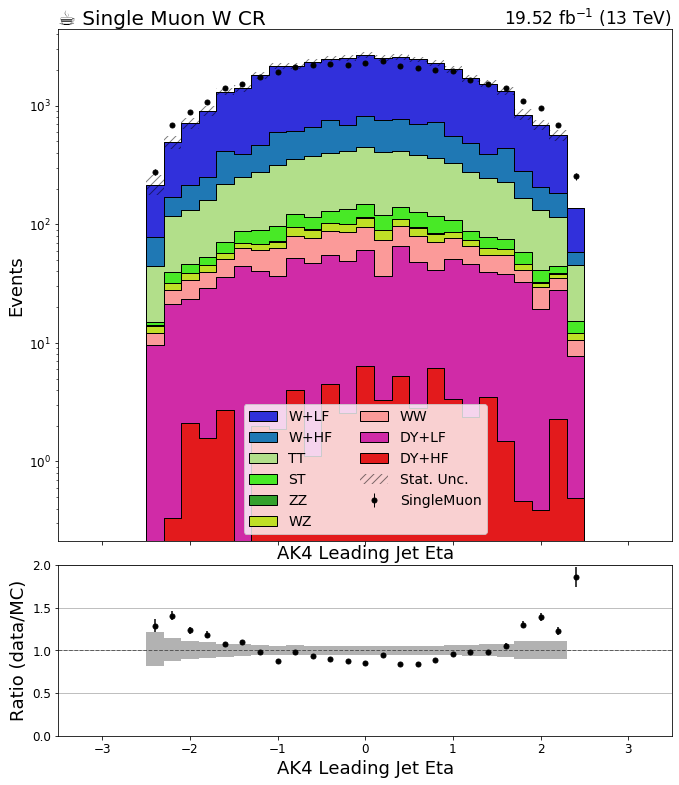

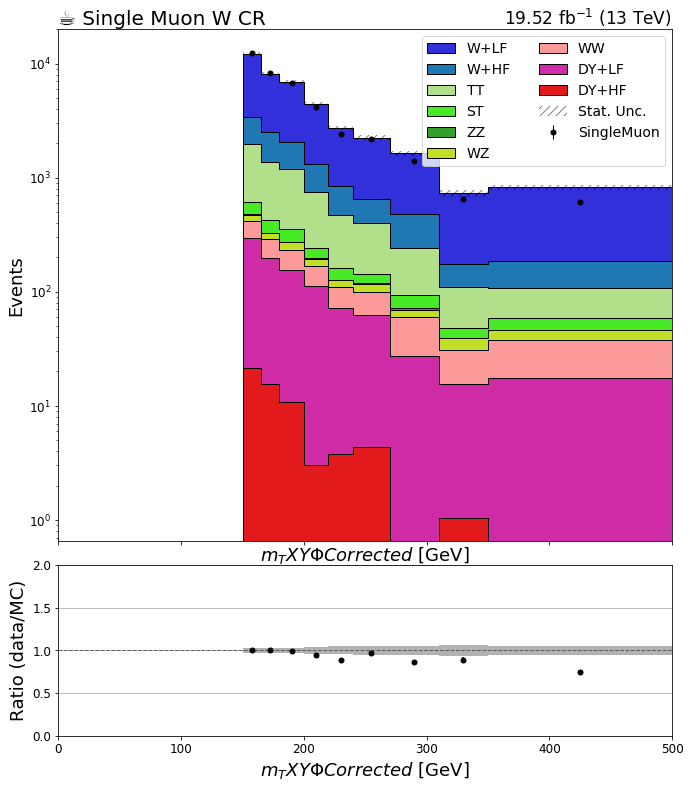

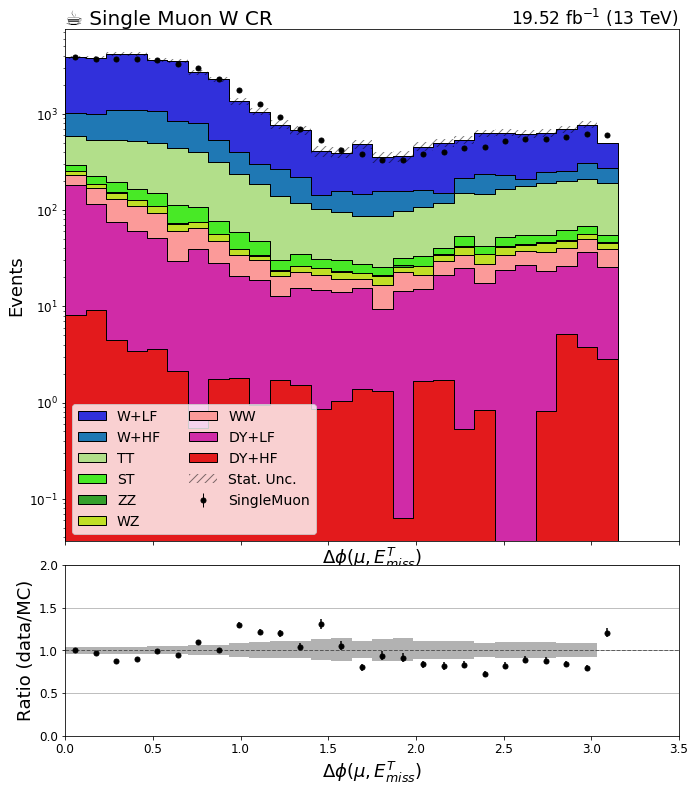

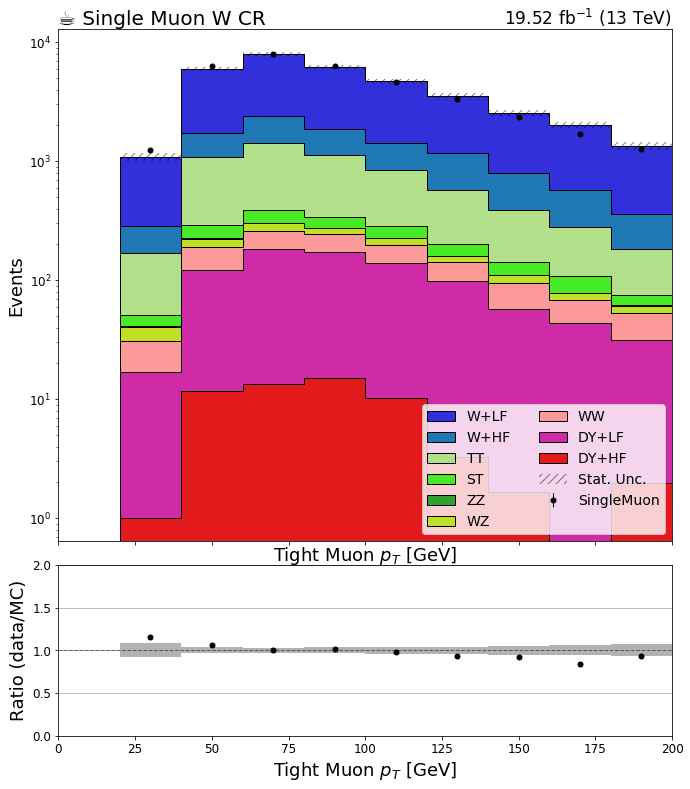

In [4]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'corrected' in key:continue
#     if 'dphi_Corr_Met_LJ' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

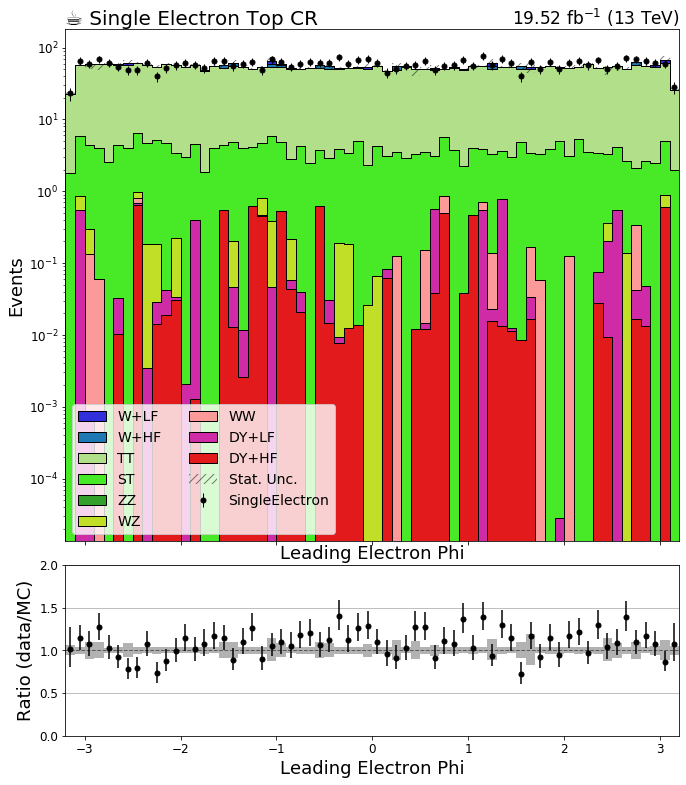

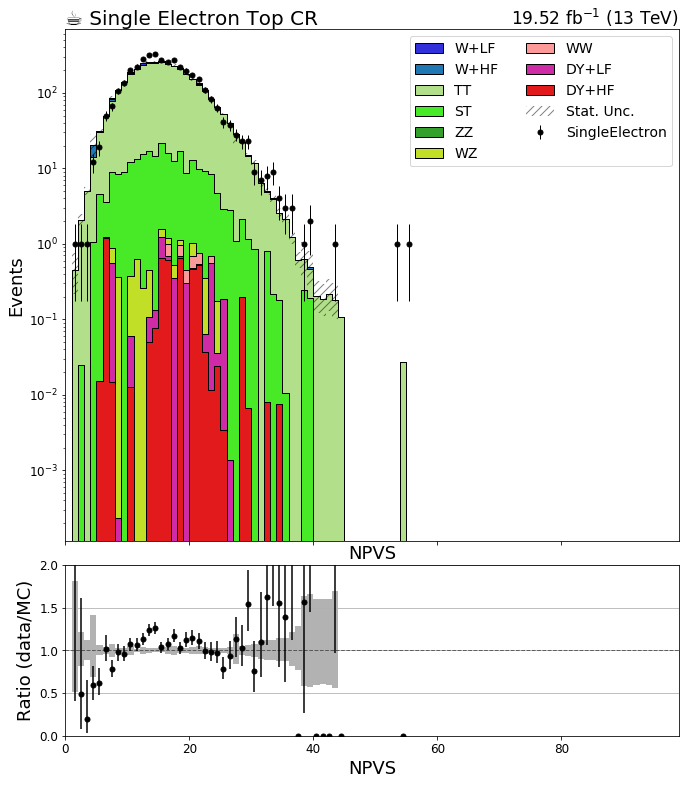

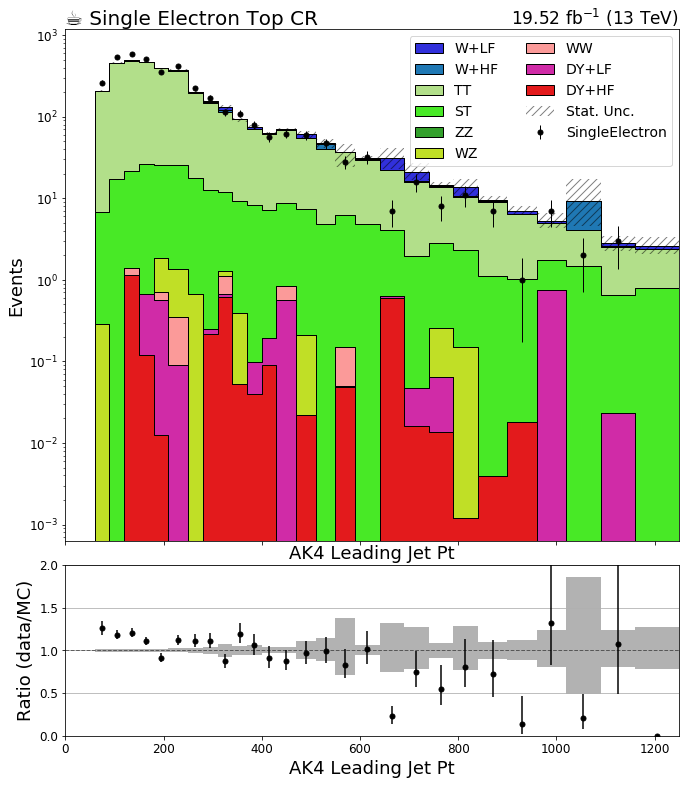

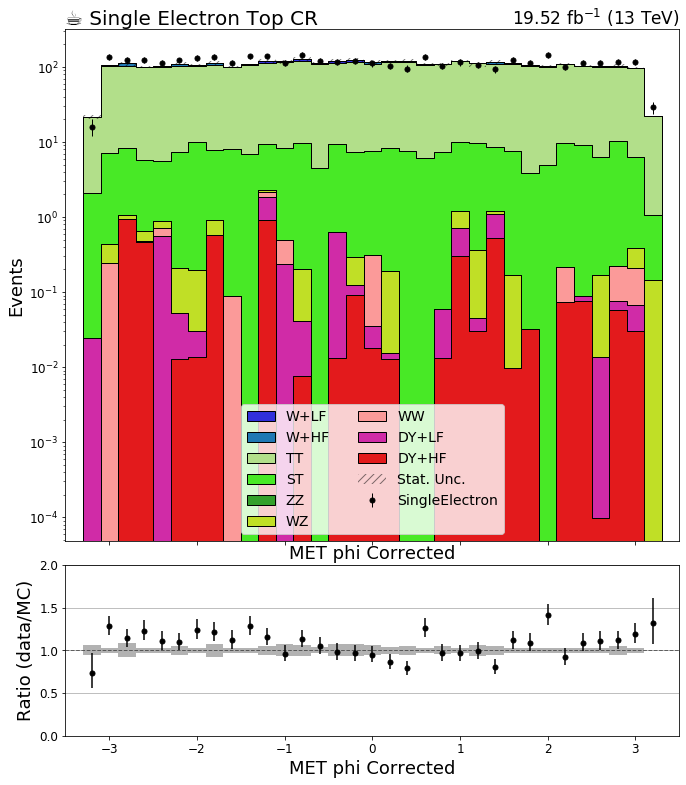

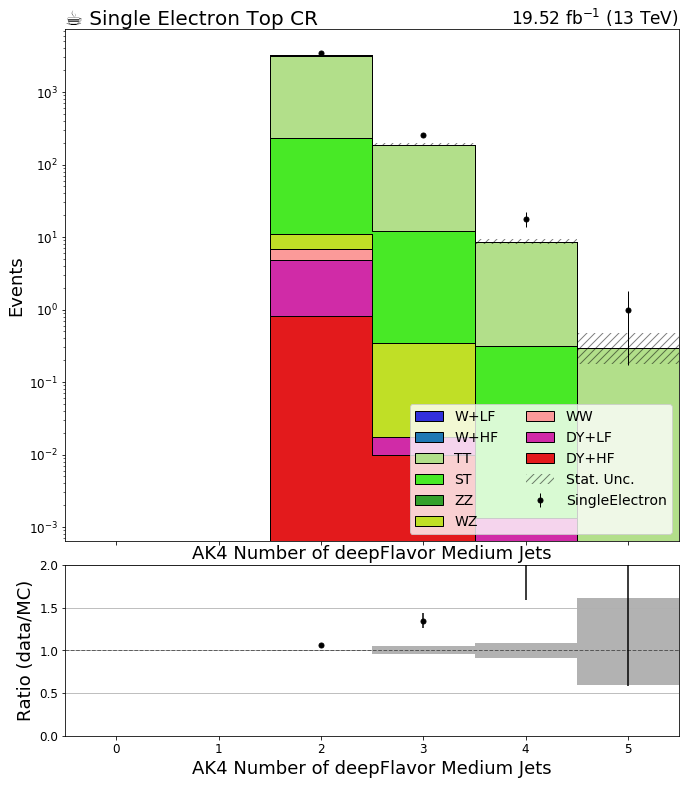

In [ ]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi_Corr_Met_LJ' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic").integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

In [ ]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2016'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi_Corr_Met_LJ' in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"19.52 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

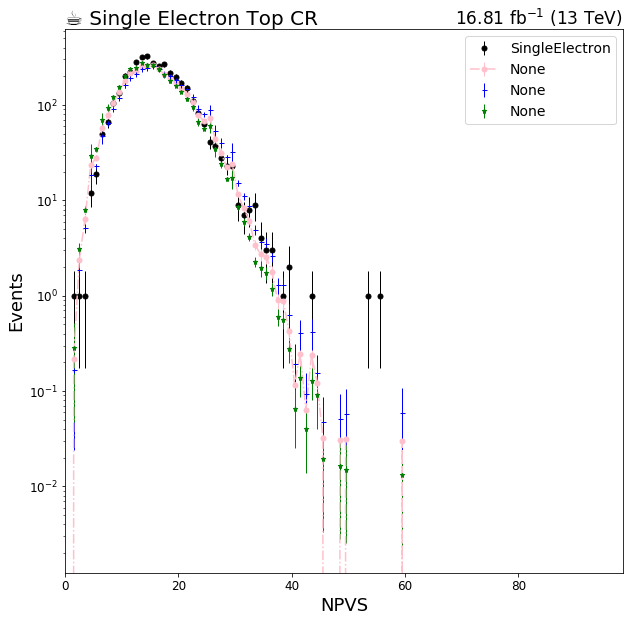

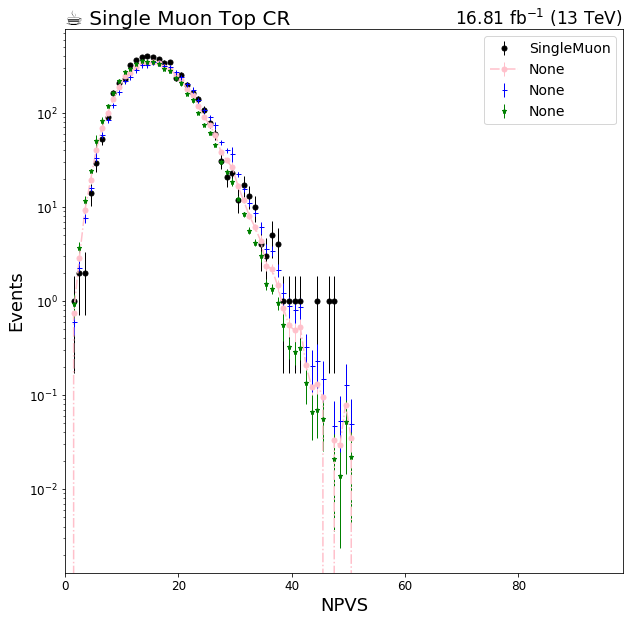

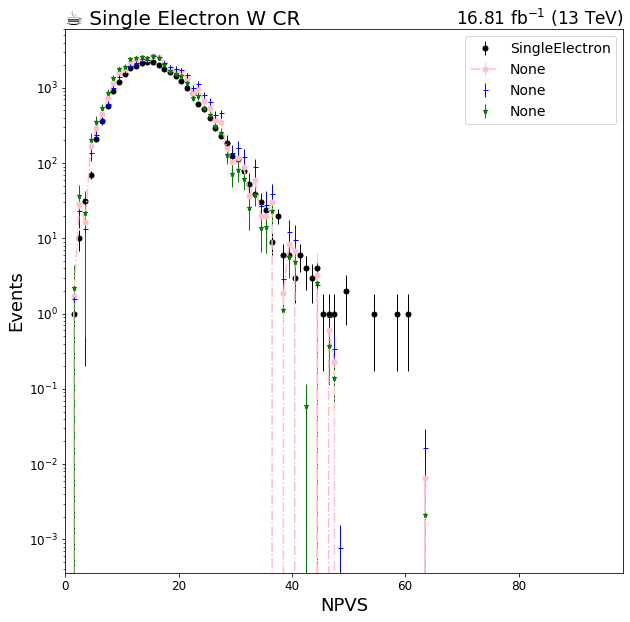

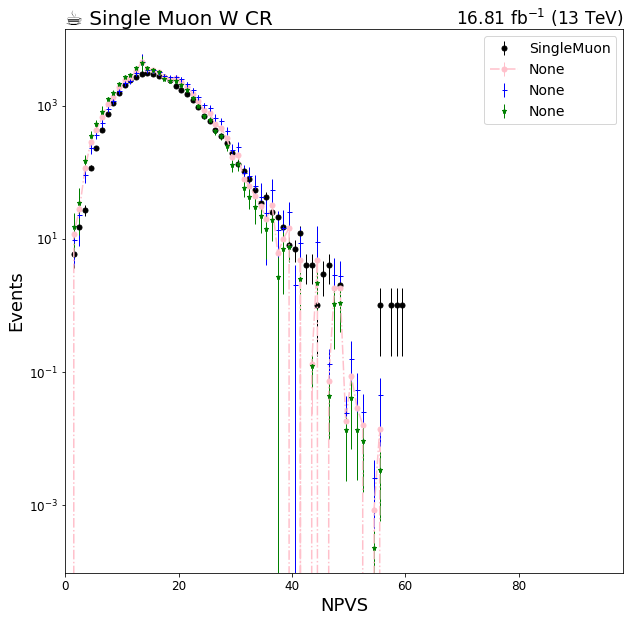

In [8]:


from coffea.hist import plot
import matplotlib.pyplot as plt

R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
for _region in bkg_hists['template'].identifiers('region'):
    if not (str(_region) not  in ['sre', 'srm']): continue
    fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 0.2,}
#     legend_opts = {'Process':"hi"}
    error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
    # nostack_fill_opts = {'alpha': 0.2, 'label': 'hi'}
    data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k',  }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_up = {'linestyle':'None', 'marker': '+', 'markersize': 5., 'color':'blue', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_down = {'linestyle':'None', 'marker': '*', 'markersize': 5., 'color':'g', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts = {'linestyle':'-.', 'marker': 'o', 'markersize': 5., 'color':'pink', }#, 'elinewidth': 1, 'emarker': '_'}

    fig, ax = plt.subplots(1,1, figsize=(10,10))
    #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
    colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                      '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                      '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']

    plot.plot1d(data_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected')[data['2016'][str(_region)]],            
    #         overlay="process",
            ax=ax,
            clear=False,
            error_opts=data_err_opts,
#                 legend_opts=legend_opts
               )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected').sum('process'),
#                 overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts,
#                 legend_opts=legend_opts
                   )
    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puUp').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_up
                   )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puDown').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_down,
                   )
    ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
    args = {'linestyle':'--', 'linewidth': 5}
    ax.autoscale(axis='x', tight=True)
    ax.set_yscale('log')
    # if(key=='dilepmass'): ax.set_xlim(50, 130)
    ax.set_ylim(.1, None)
    ax.autoscale()
    leg = ax.legend(ncol=1, loc='best')
    coffee = plt.text(0., 1., u"☕ "+R[str(_region).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
    lumi = plt.text(1., 1., r"16.81 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)

Text(0.5, 1.0, '2016 preVFP wjete')

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


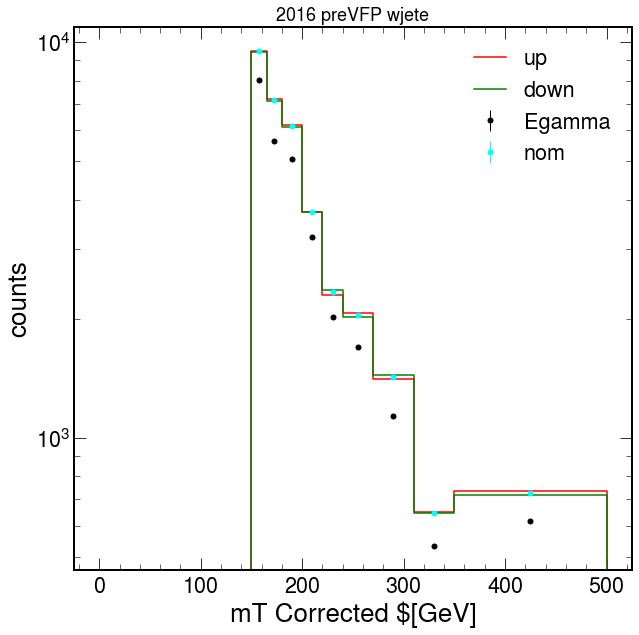

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
# plt.style.use(hep.style.ROOT)

j = 'wjete'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="Egamma")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

Text(0.5, 1.0, '2016 preVFP wjetm')

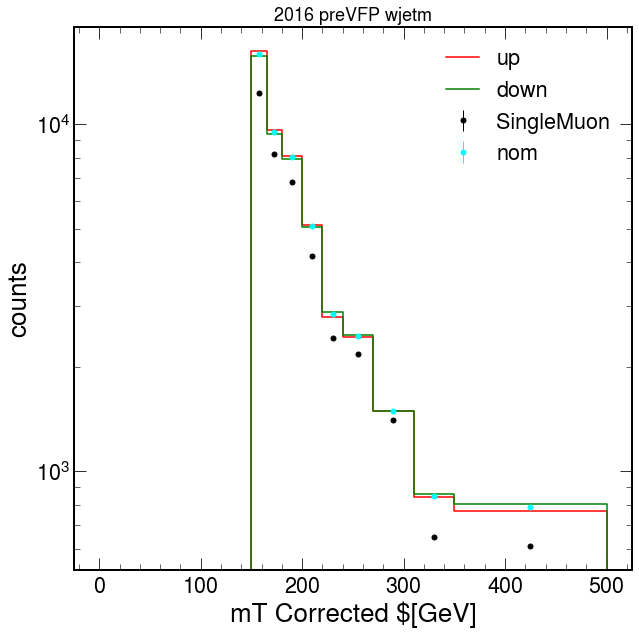

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'wjetm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

Text(0.5, 1.0, '2016 preVFP ttbarm')

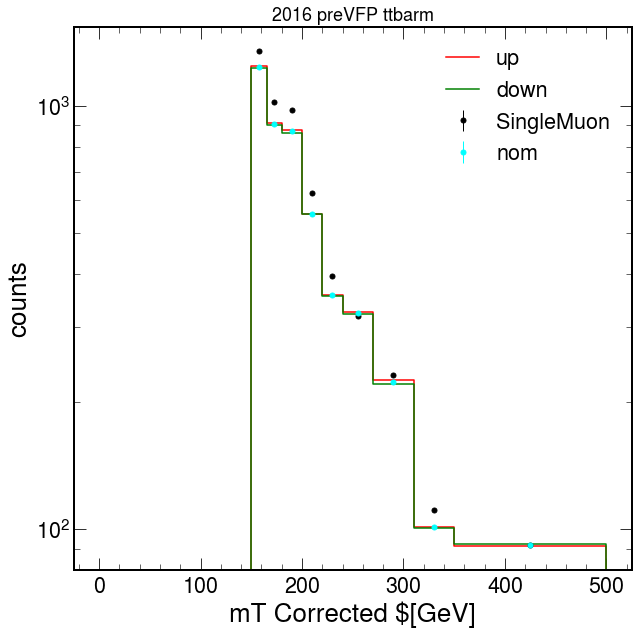

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'ttbarm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

Text(0.5, 1.0, '2016 preVFP ttbarm')

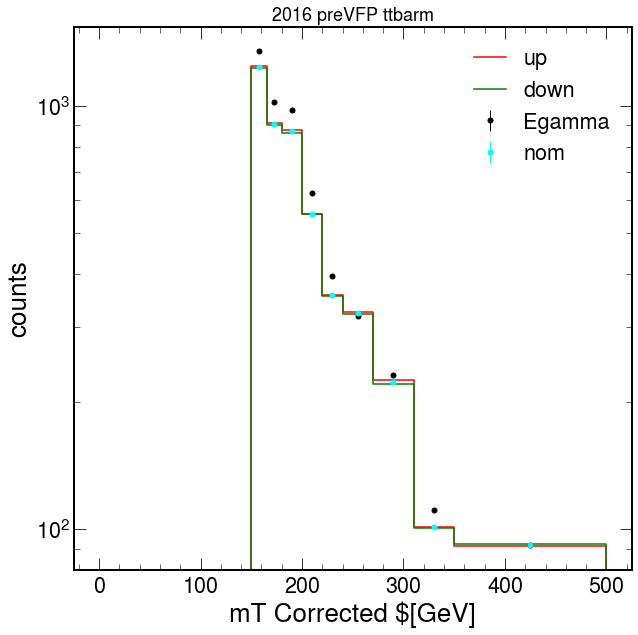

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
# plt.style.use(hep.style.ROOT)

j = 'ttbarm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="Egamma")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2016 preVFP "+j)

In [61]:
nom=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', 'nominal').sum('process').sum('npvs').values()[()]
up=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', 'METunclUp').sum('process').sum('npvs').values()[()]
down=bkg_hists['template'].integrate('region', 'ttbare').integrate('systematic', 'METunclDown').sum('process').sum('npvs').values()[()]

In [62]:
up[nom<=0]=1
down[nom<=0]=1

In [63]:
up[~(nom<=0)] /= nom[~(nom<=0)]
down[~(nom<=0)] /= nom[~(nom<=0)]

In [64]:
up

array([1.        , 1.        , 0.98793273, 1.05161463, 1.0870678 ,
       0.98029402, 1.01484561, 0.92144899, 1.13383339, 1.02998466,
       0.97423762])

In [65]:
down

array([1.        , 1.        , 0.94296615, 1.03003422, 1.01987031,
       0.95926222, 0.93918632, 0.97697362, 1.04560723, 0.99589909,
       0.99302184])

In [33]:
up

array([    0.        ,     0.        , 29053.10833436, 17245.88359442,
       15146.58016043, 39821.05077794,  4956.54465419,  4278.76192713,
        2454.51915451,  1533.94923483,  1232.21311912])

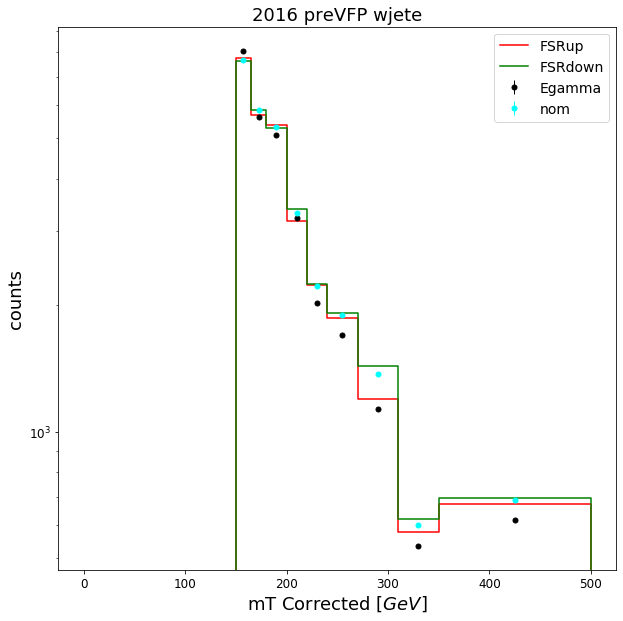

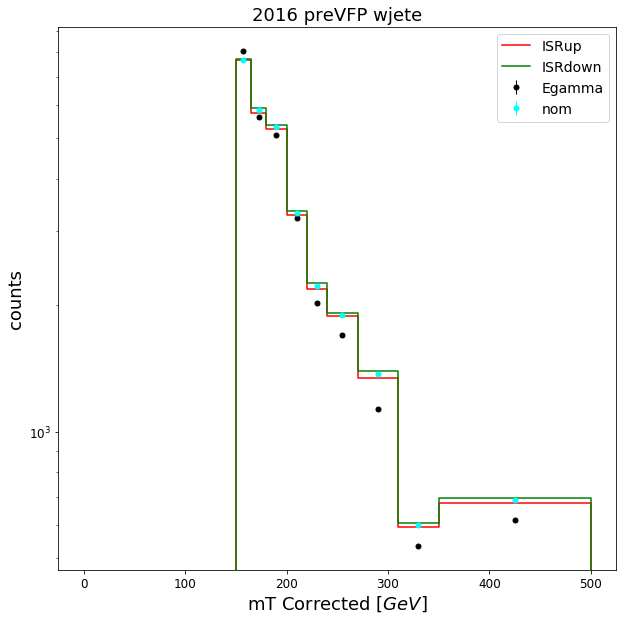

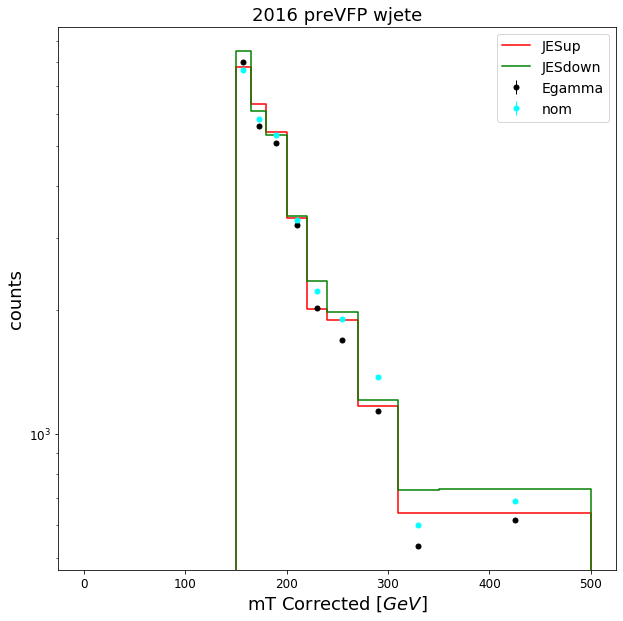

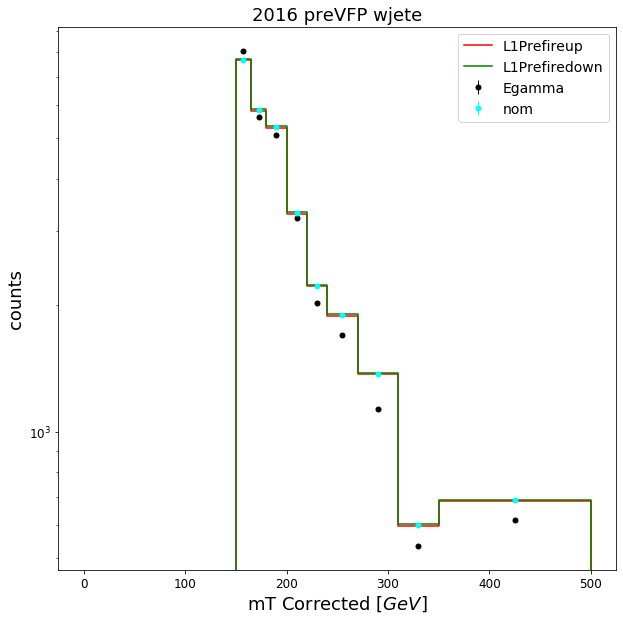

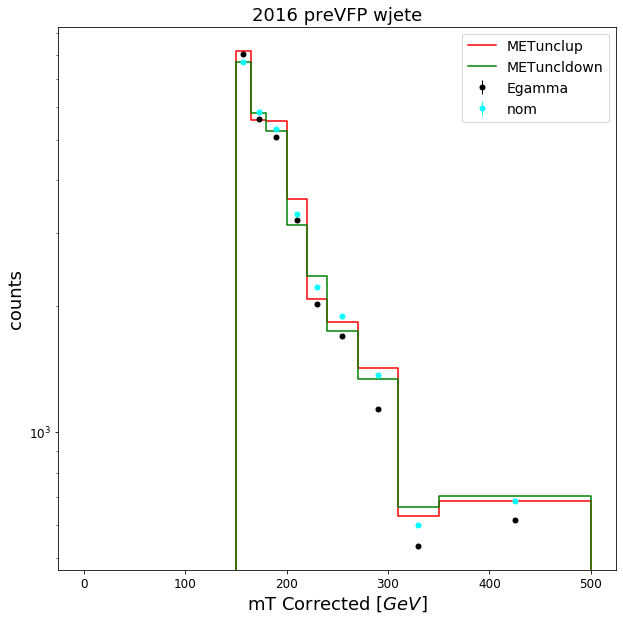

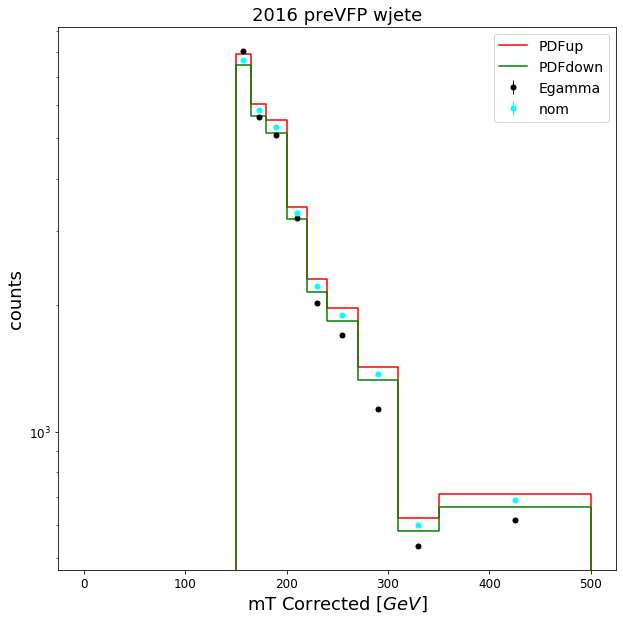

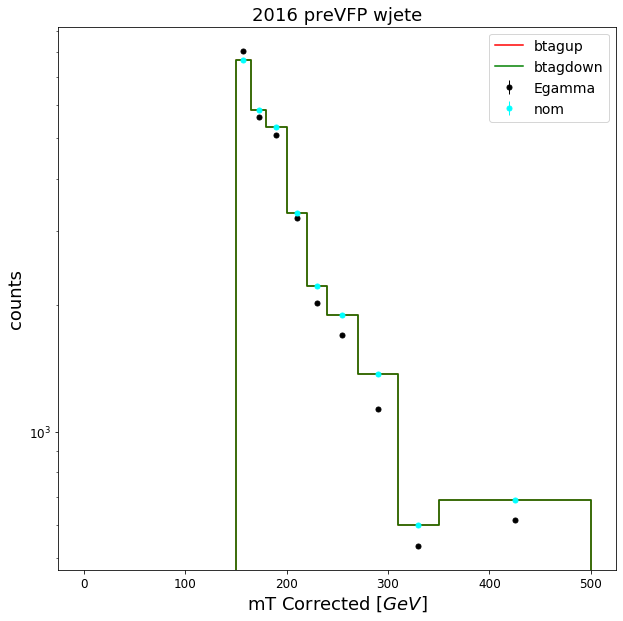

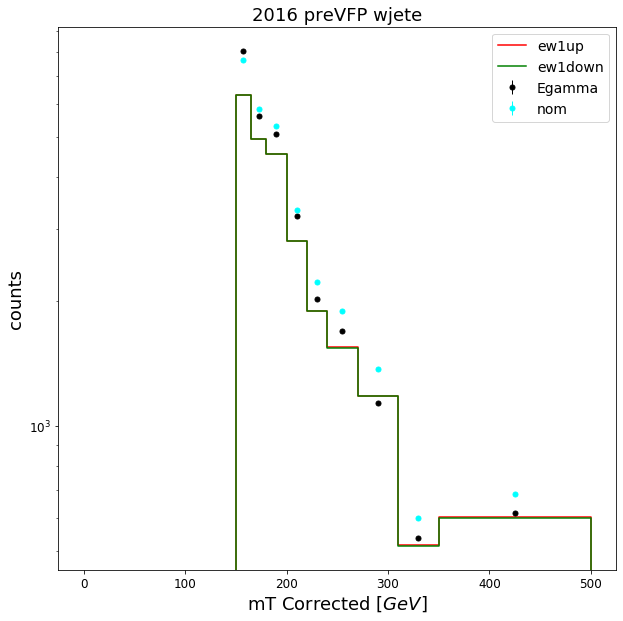

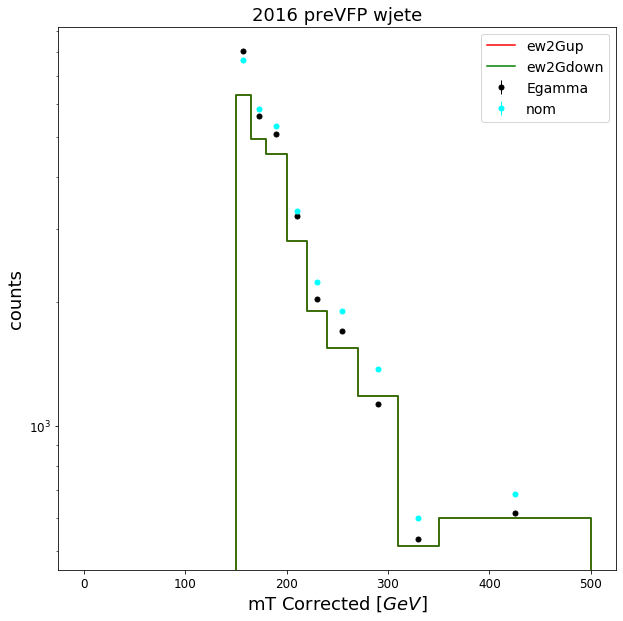

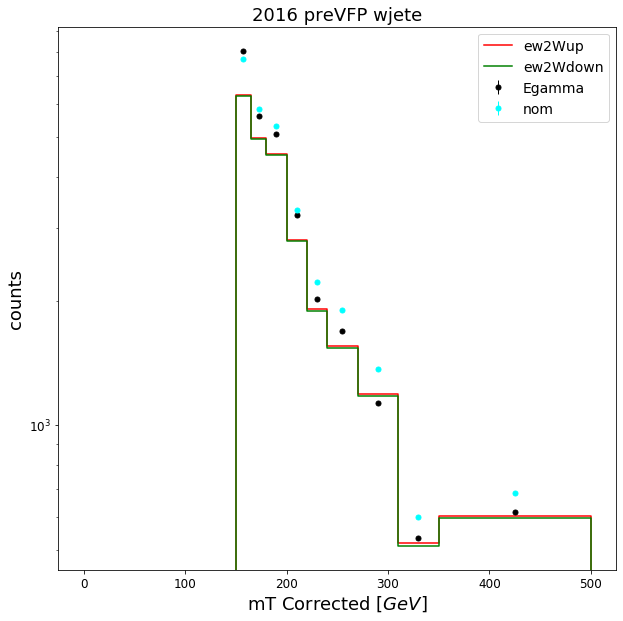

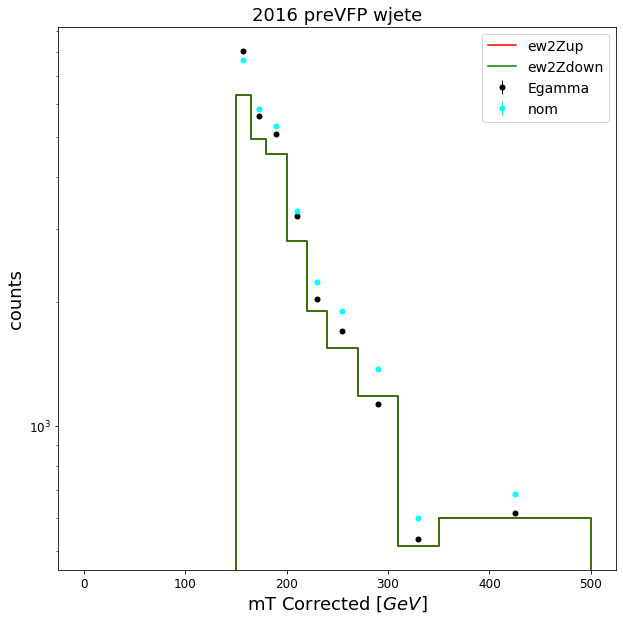

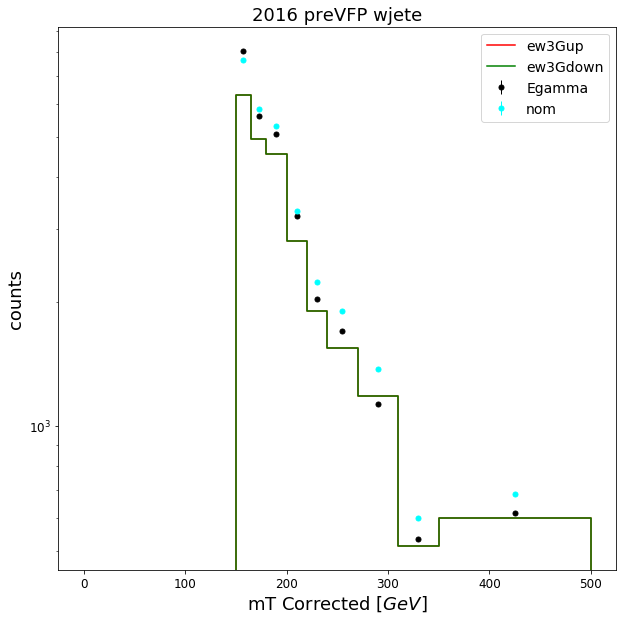

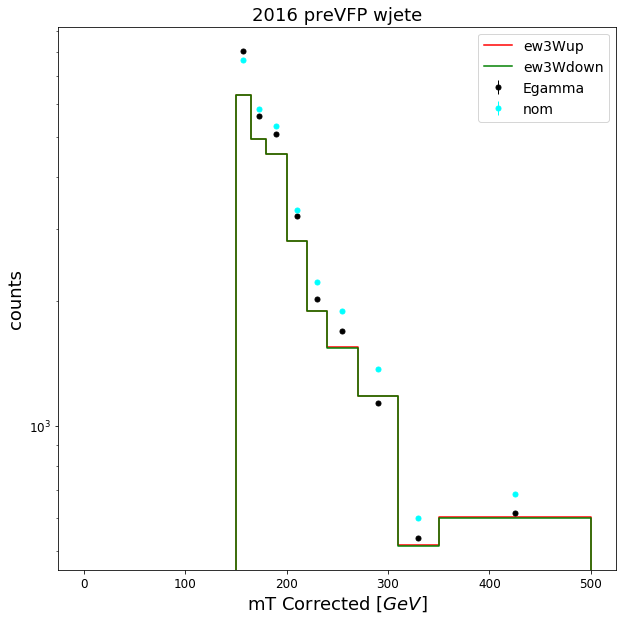

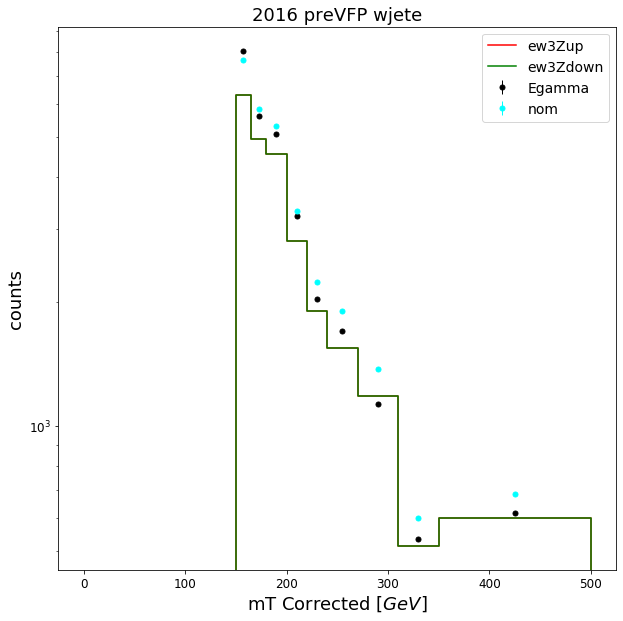

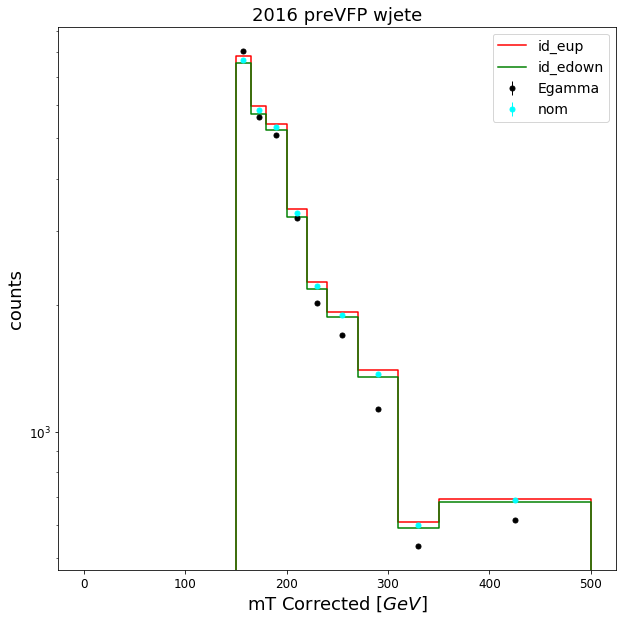

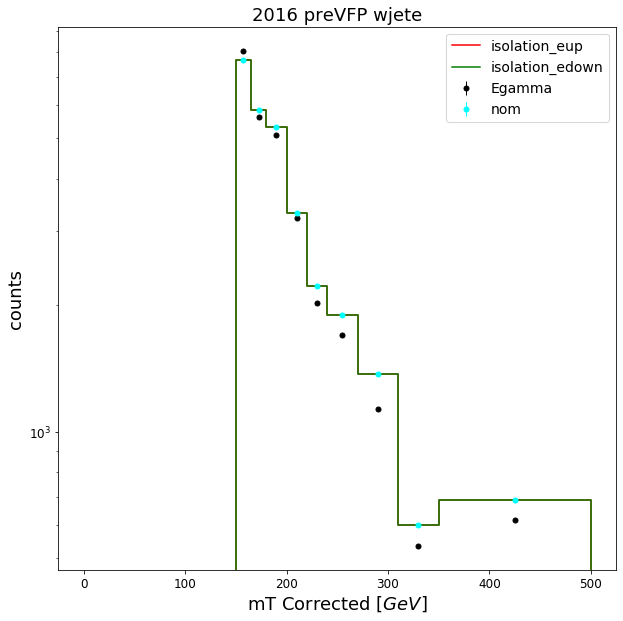

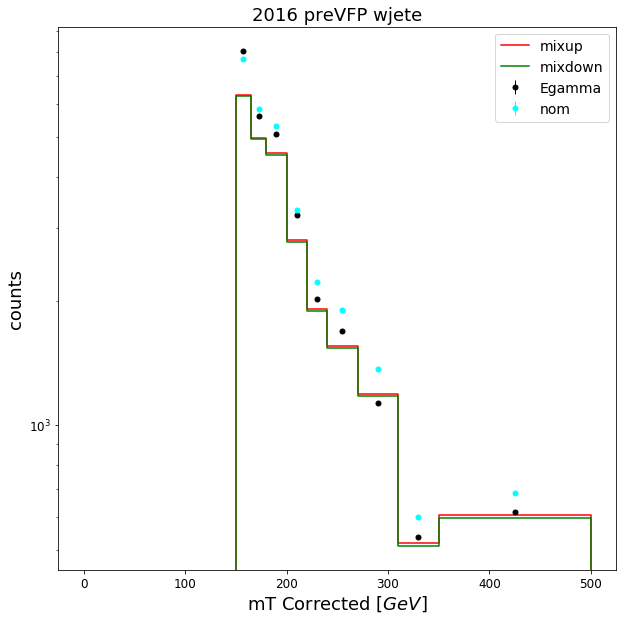

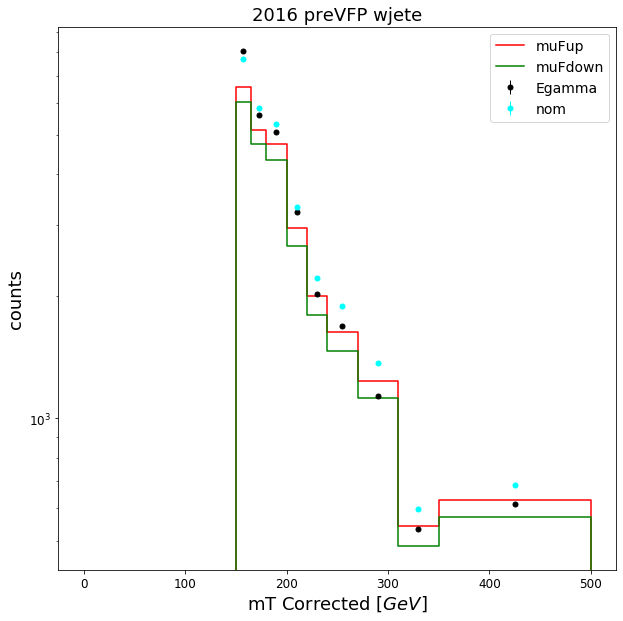

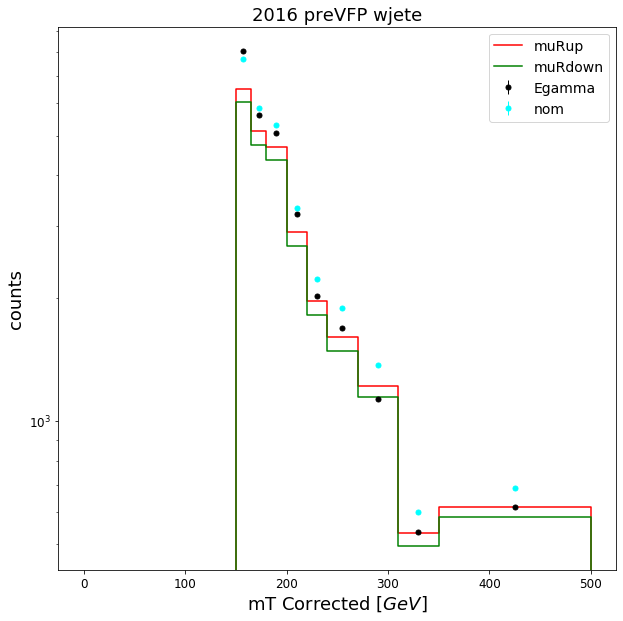

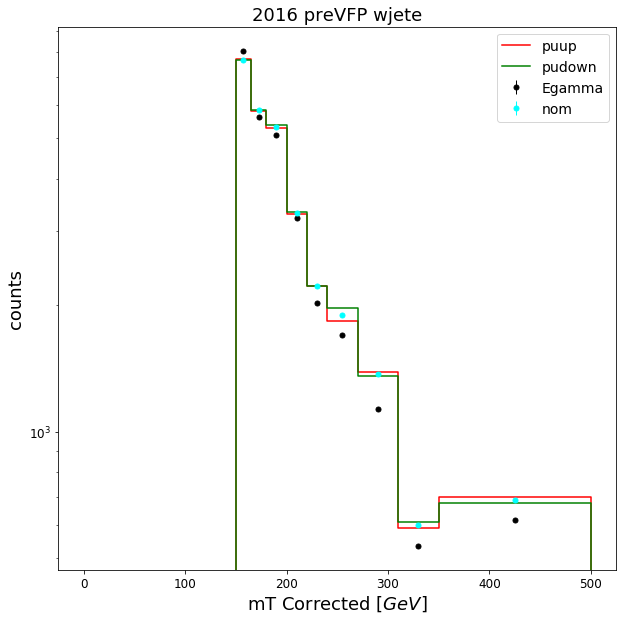

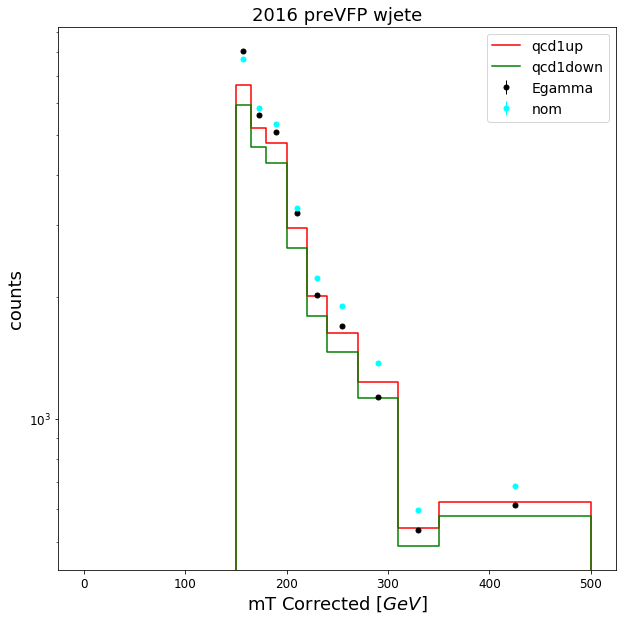

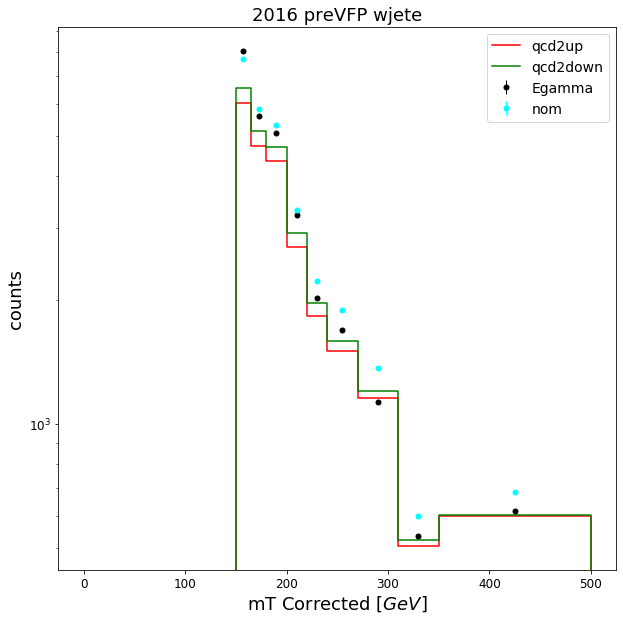

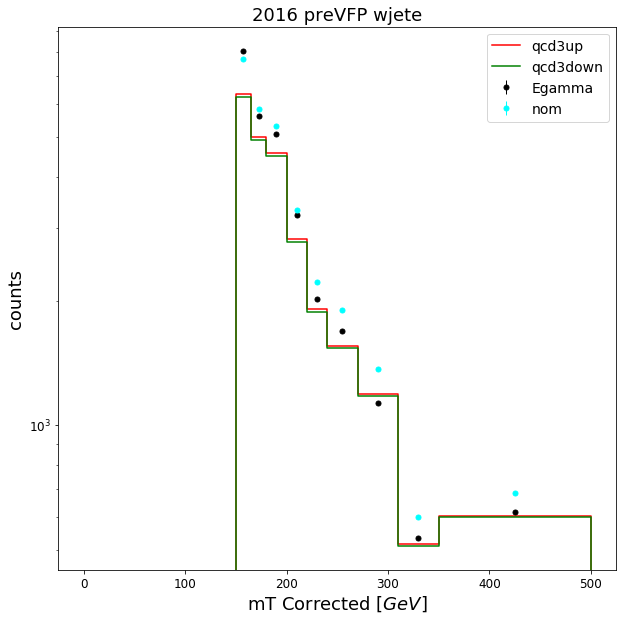

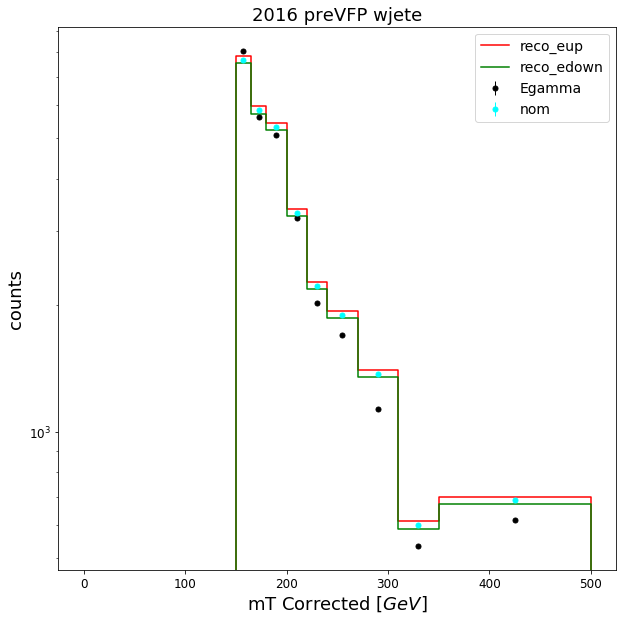

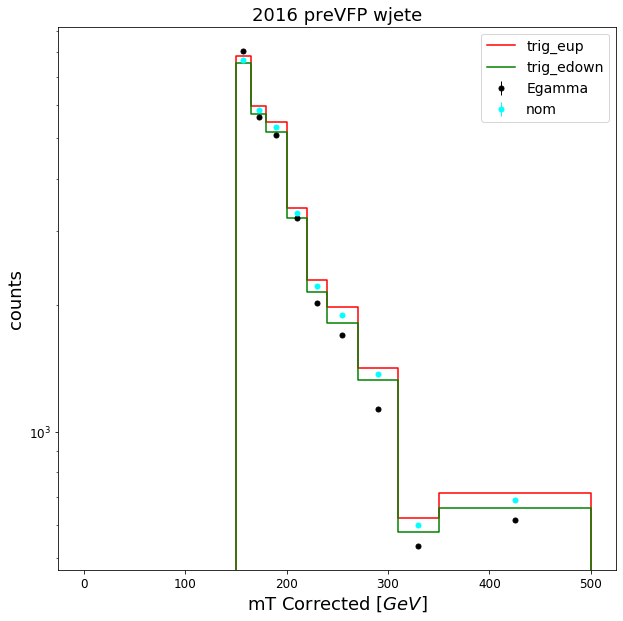

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjete'
systematics = []
for syst in bkg_hists['template'].integrate('region', cr).identifiers('systematic'):
    if (re.search("Up$", str(syst))):
        systematics.append(str(syst)[:-2])


for sys in systematics:
#     print(sys)
    bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
    data = data_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('npvs').integrate('process').values()[()]
    nom = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('npvs').integrate('process').values()[()]

    f, ax = plt.subplots(figsize=[10,10])
    hep.histplot(data, bins,color='black',histtype='errorbar',
    label="Egamma")
    hep.histplot(up, bins, color='red',
    label=sys+"up")
    hep.histplot(down, bins, color='green',
    label=sys+"down")
    hep.histplot(nom, bins, color='cyan',histtype='errorbar',
    label="nom")
    ax.legend()
    ax.set_yscale('log')
    ax.set_ylabel("counts")
    ax.set_xlabel("mT Corrected $[GeV]$")
    ax.set_title("2016 preVFP "+cr)